ADVANCED STATISTICAL TIME-SERIES ANALYSIS
Project directory: C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand
Dataset shape: (720, 6)
Observation period: 2023-01-12 to 2025-12-21
Observed records: 720
Calendar days: 1075
Missing calendar dates: 355


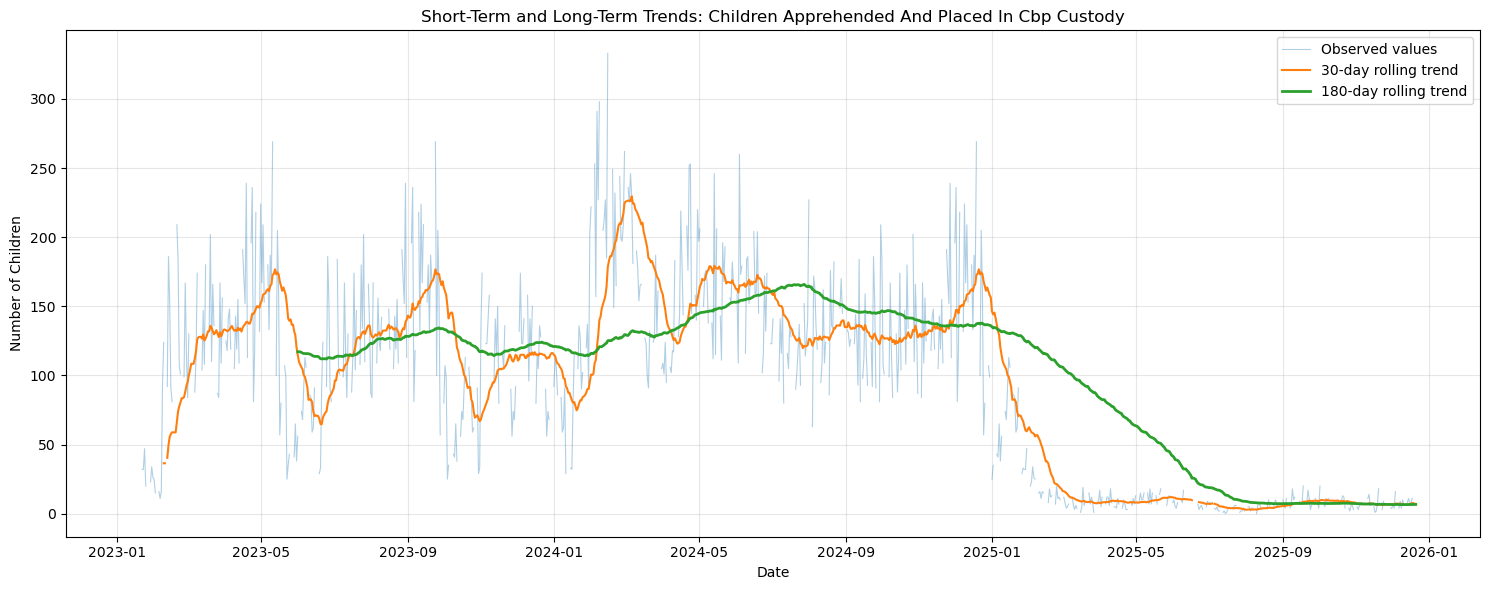

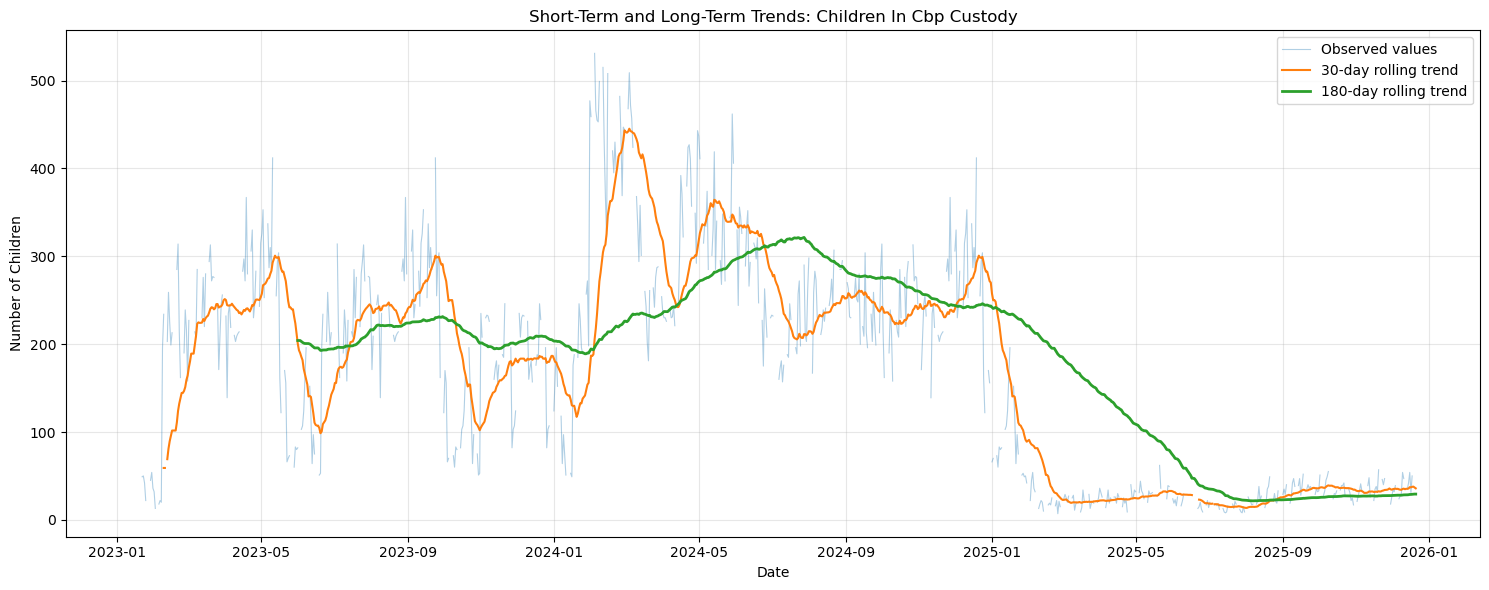

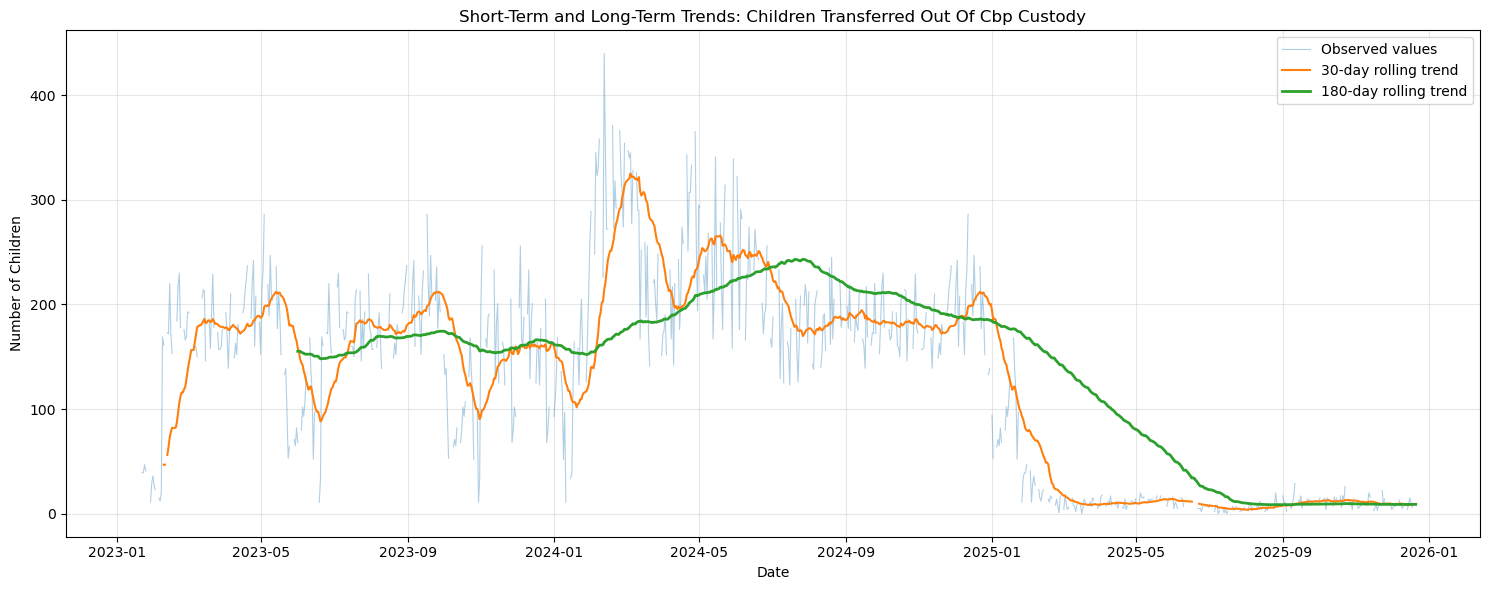

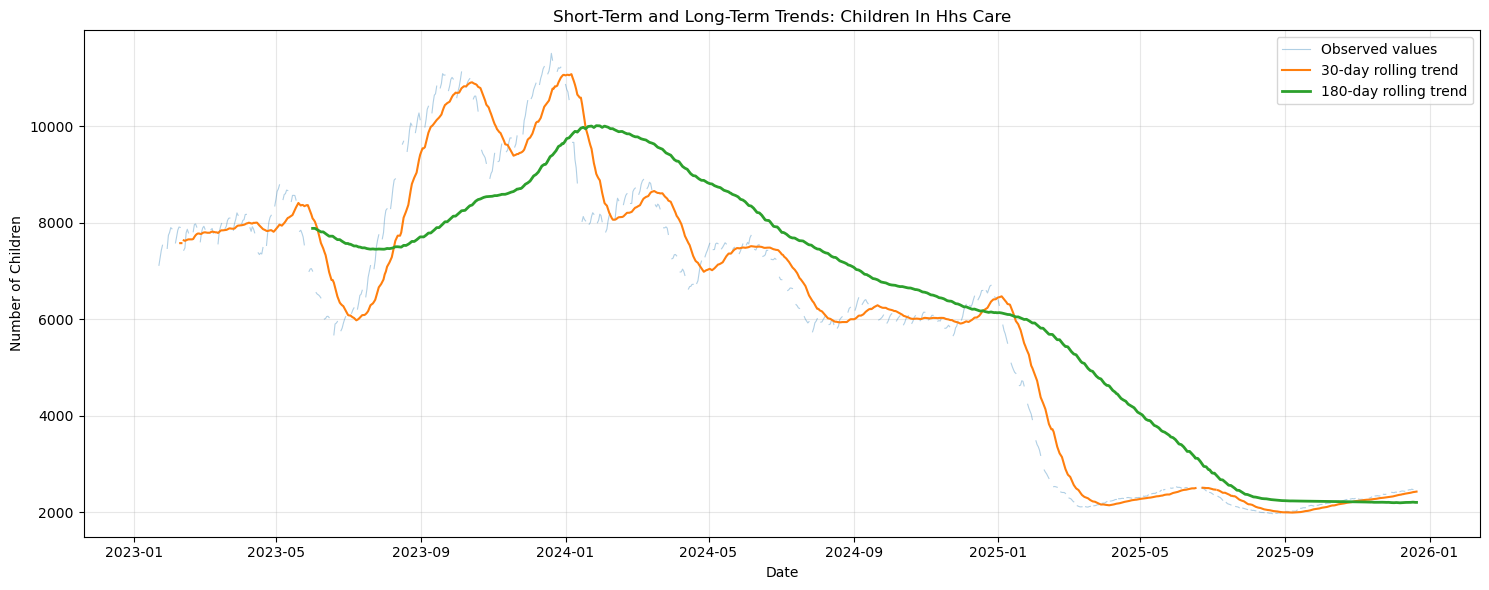

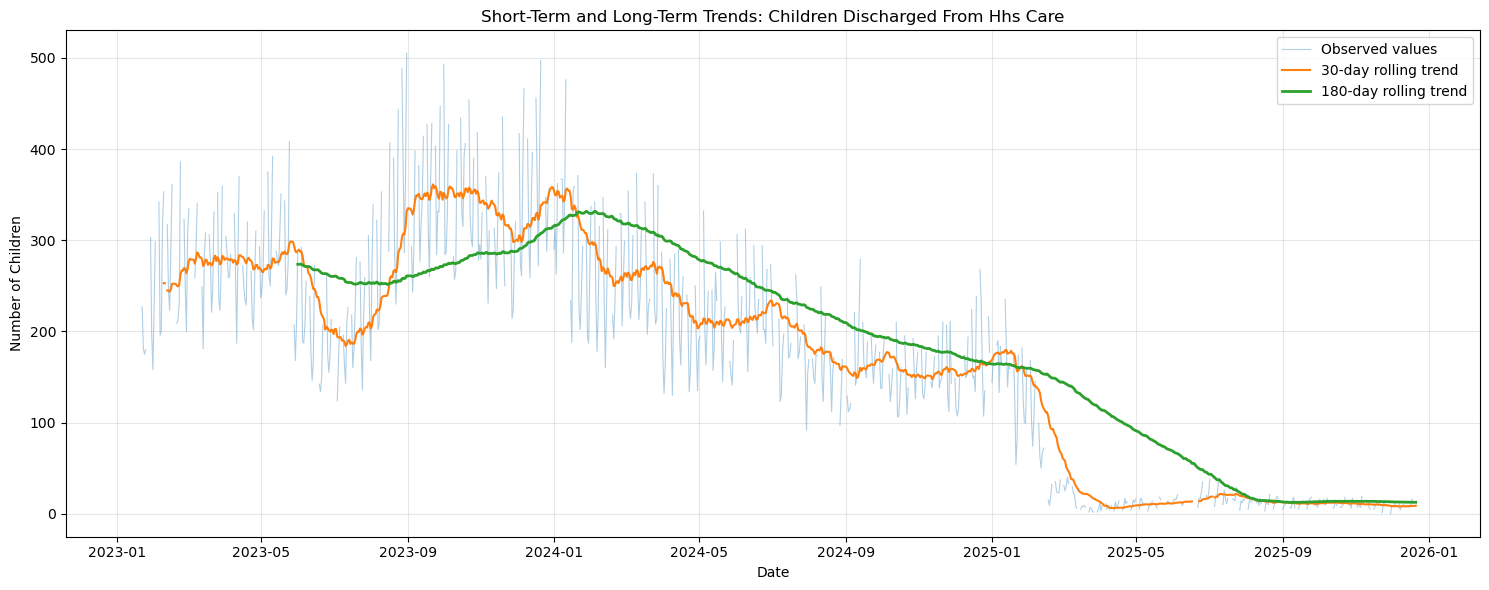


LONG-TERM AND SHORT-TERM TREND ANALYSIS
                                      Variable  Long_Term_Trend_Slope_Per_Day  Trend_Slope_Per_30_Days  Trend_R_Squared Overall_Trend
children_apprehended_and_placed_in_cbp_custody                        -0.1363                  -4.0878           0.3315    Decreasing
                       children_in_cbp_custody                        -0.2222                  -6.6650           0.2913    Decreasing
       children_transferred_out_of_cbp_custody                        -0.1856                  -5.5693           0.3429    Decreasing
                          children_in_hhs_care                        -7.7402                -232.2064           0.7034    Decreasing
             children_discharged_from_hhs_care                        -0.3385                 -10.1555           0.6834    Decreasing


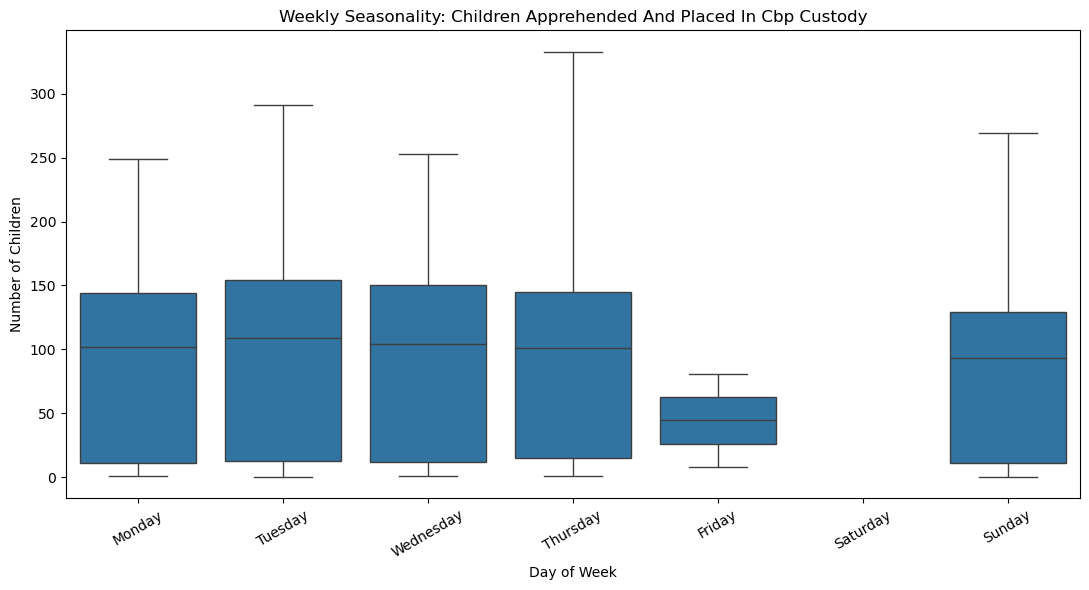

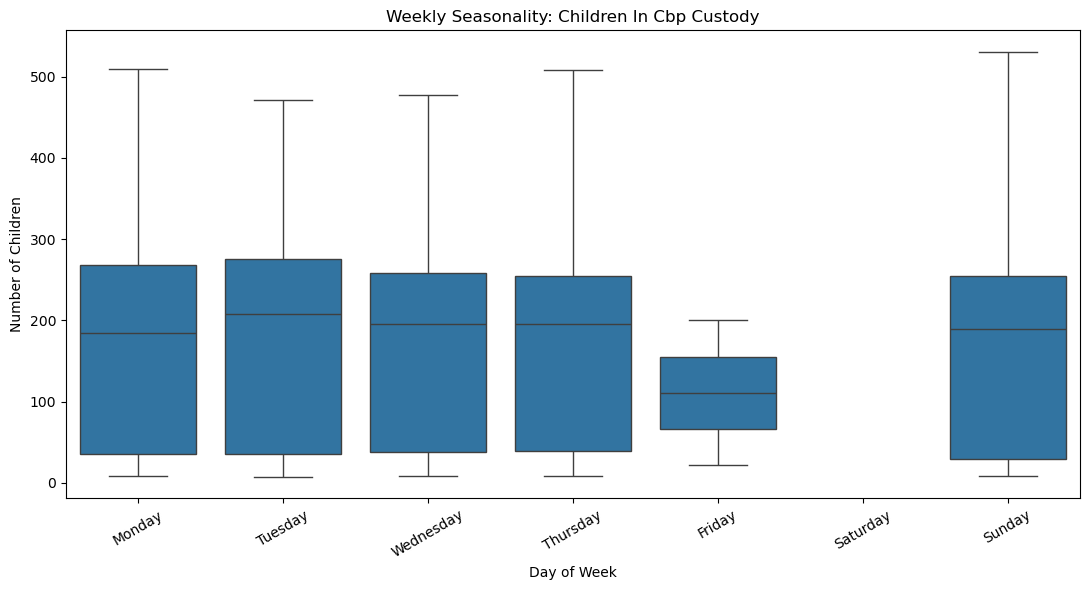

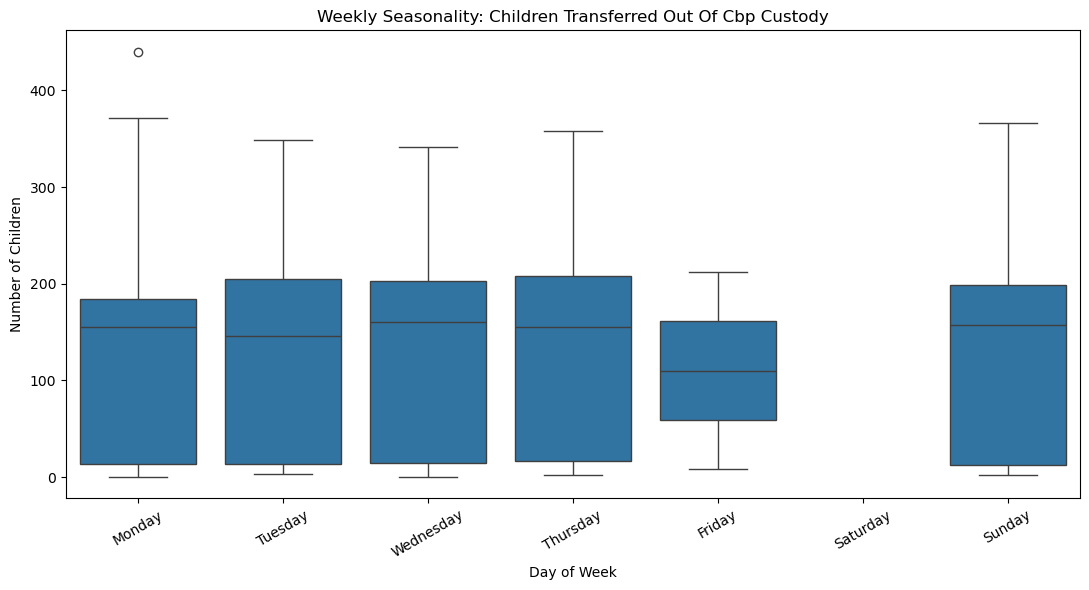

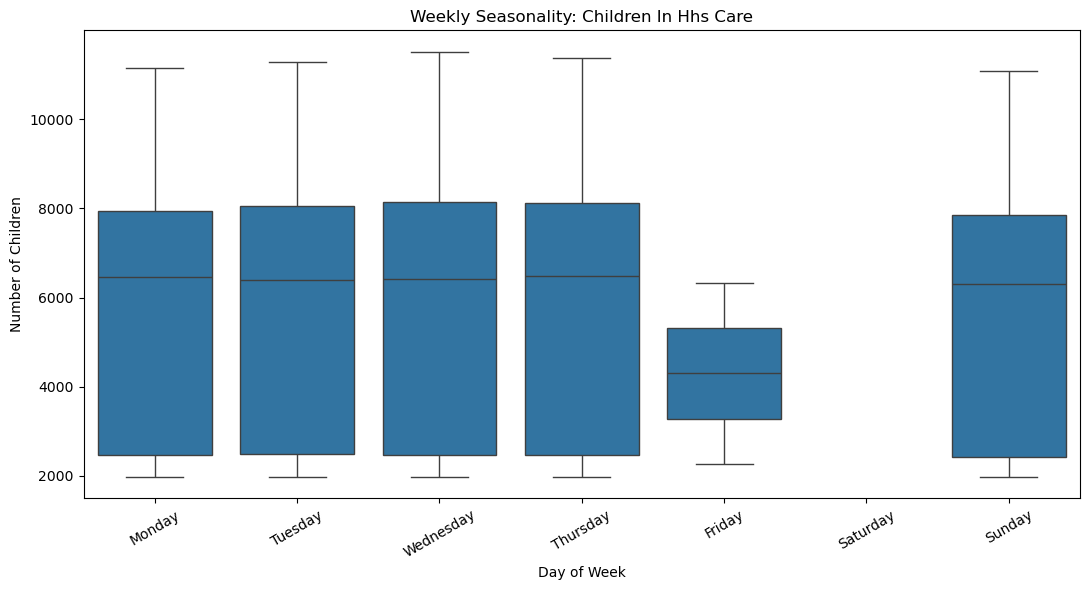

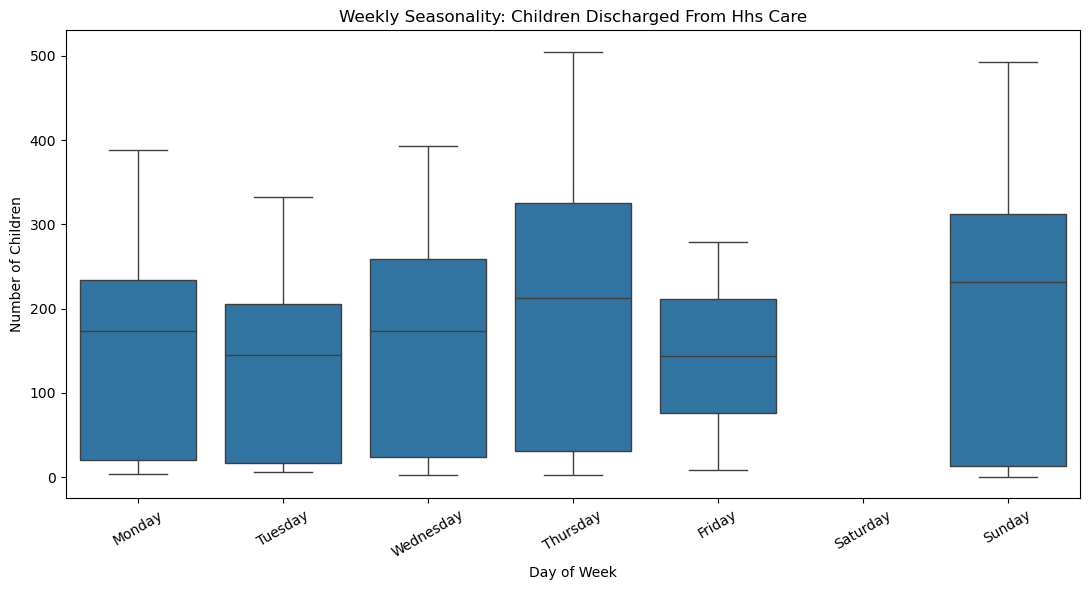


WEEKDAY AND WEEKEND COMPARISON
                                      Variable  Weekday_Count  Weekend_Count  Weekday_Mean  Weekend_Mean  Weekday_Median  Weekend_Median  Mann_Whitney_Statistic  P_Value  Significant_At_5_Percent
children_apprehended_and_placed_in_cbp_custody            590            130       94.6881       88.2385           101.5            93.5                 41145.5   0.1929                     False
                       children_in_cbp_custody            590            130      171.9576      169.3923           196.0           190.0                 39918.0   0.4653                     False
       children_transferred_out_of_cbp_custody            590            130      128.3610      130.0615           156.5           157.5                 38515.5   0.9387                     False
                          children_in_hhs_care            590            130     6102.3153     5875.0154          6447.0          6297.0                 40429.0   0.3329               

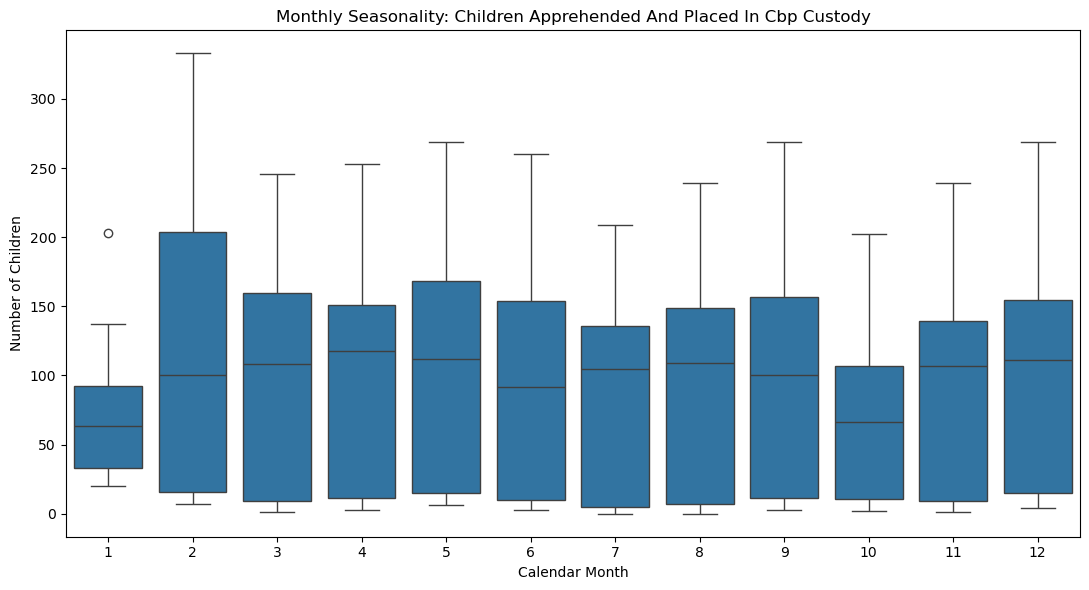

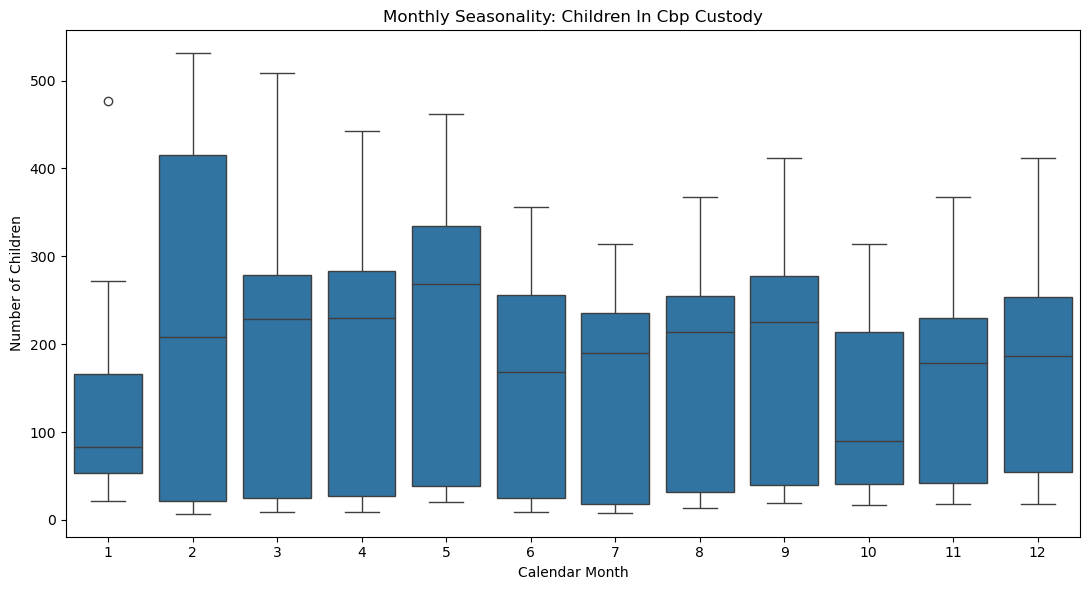

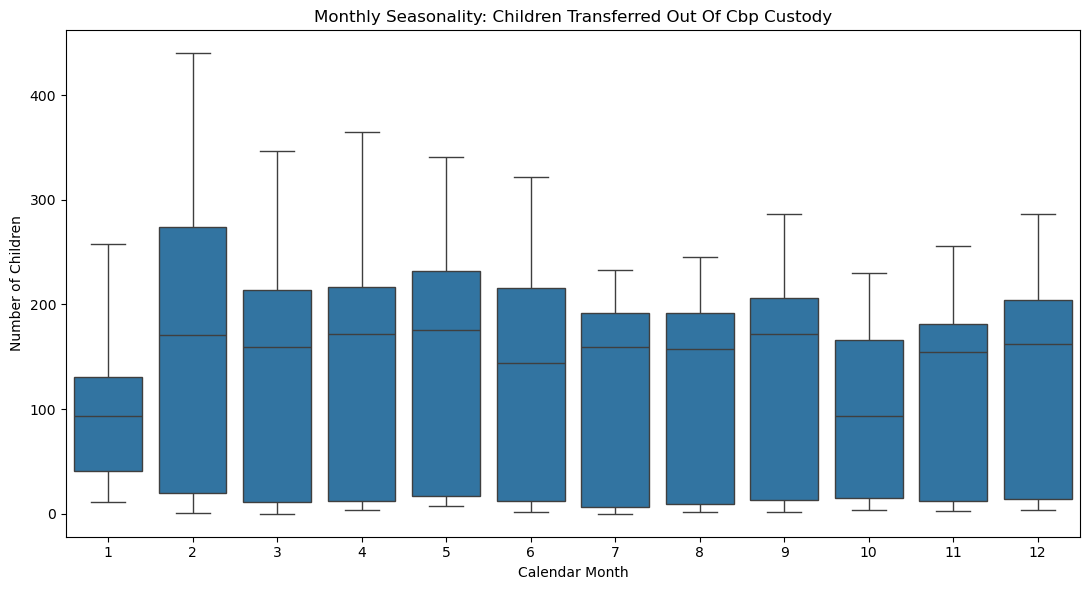

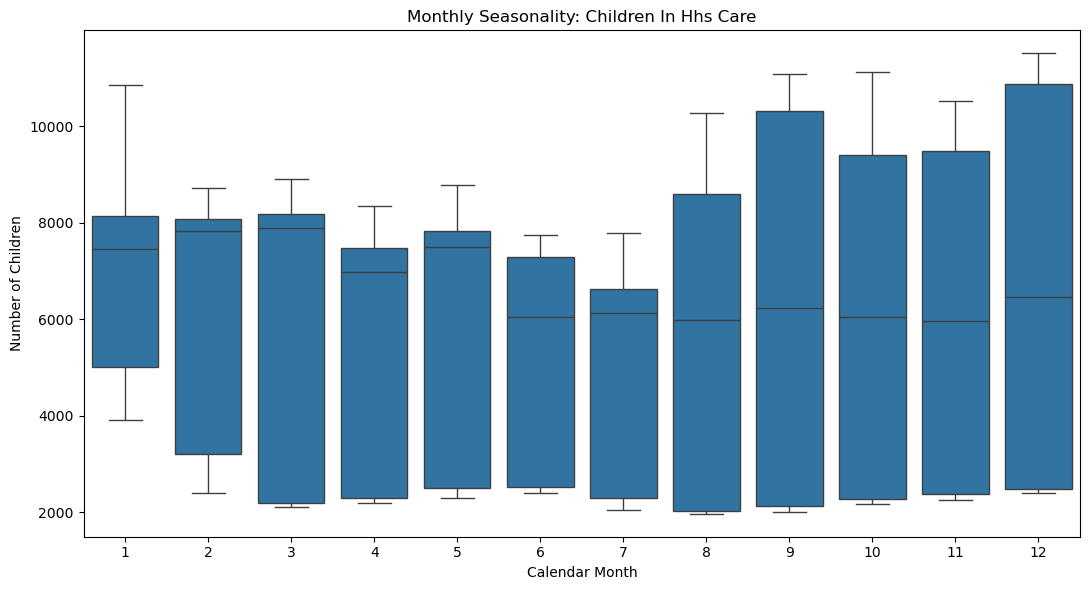

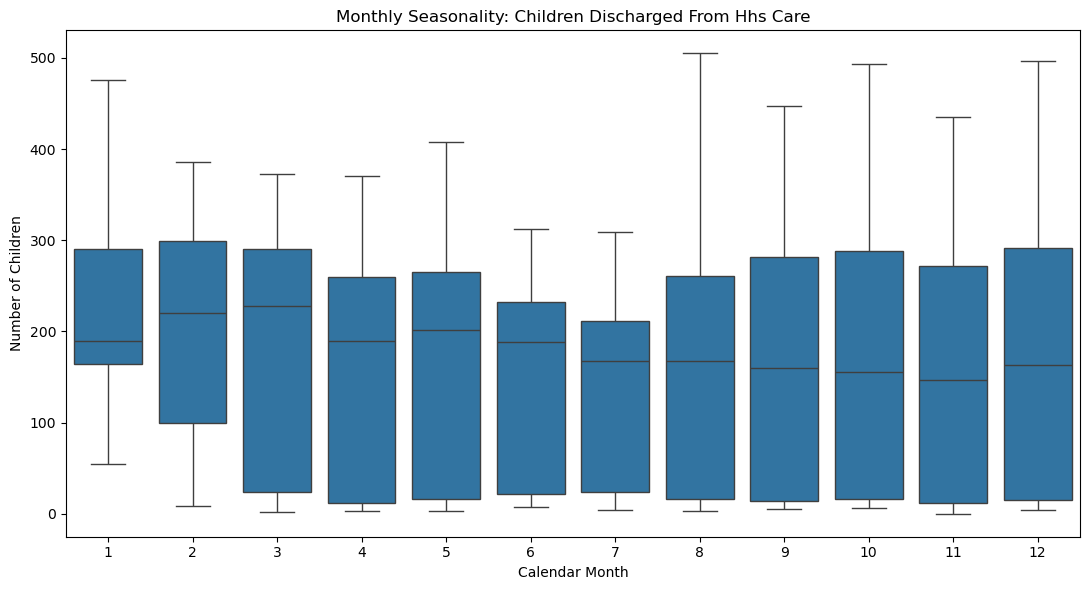

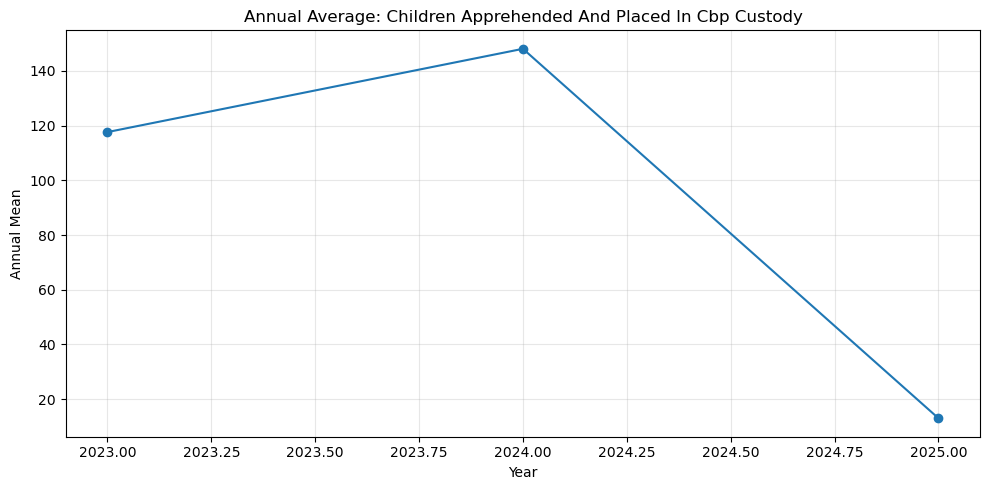

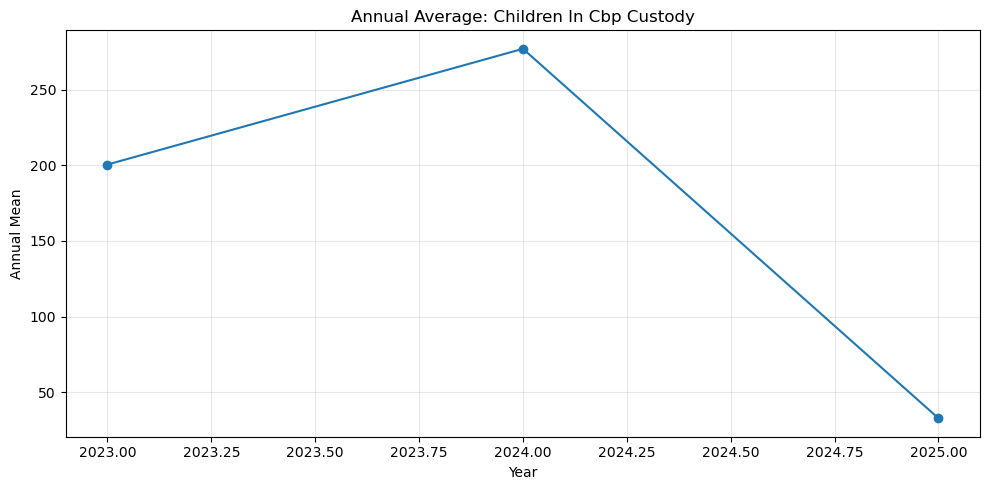

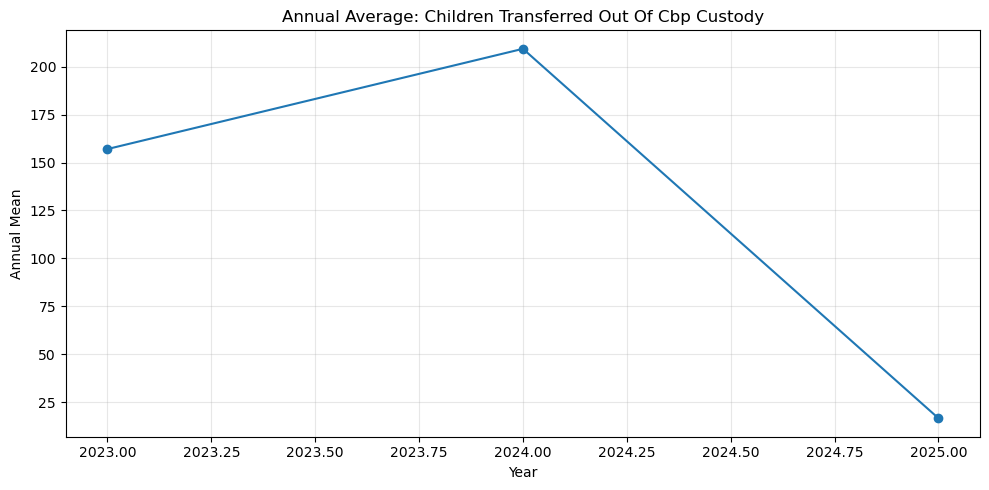

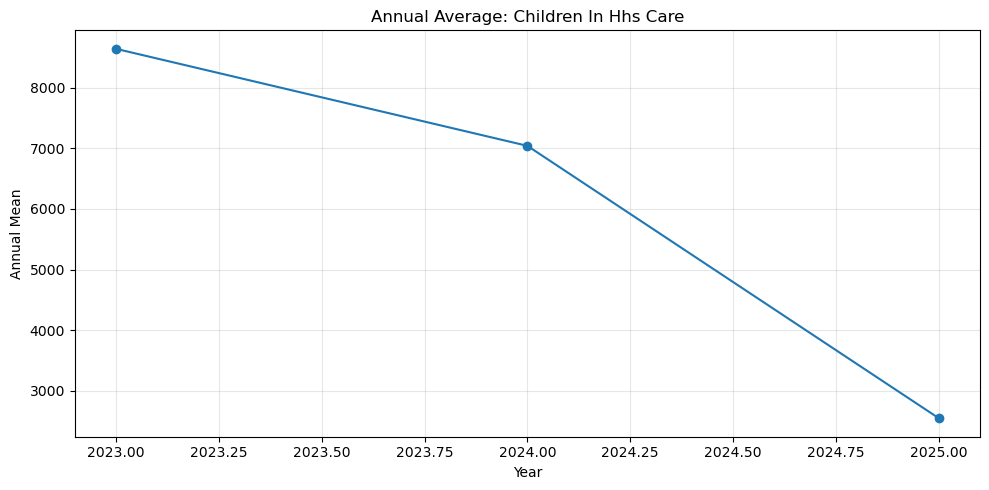

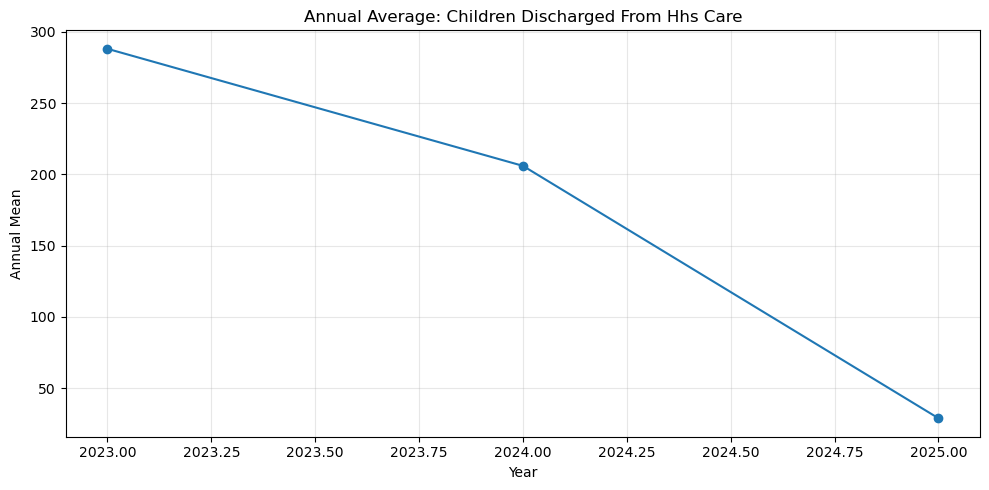

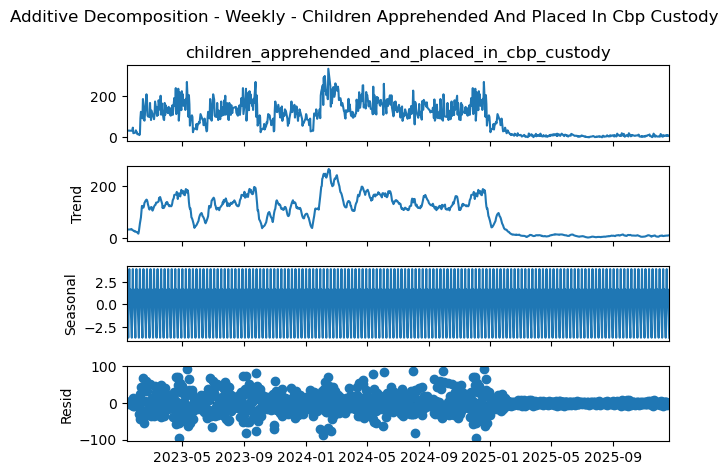

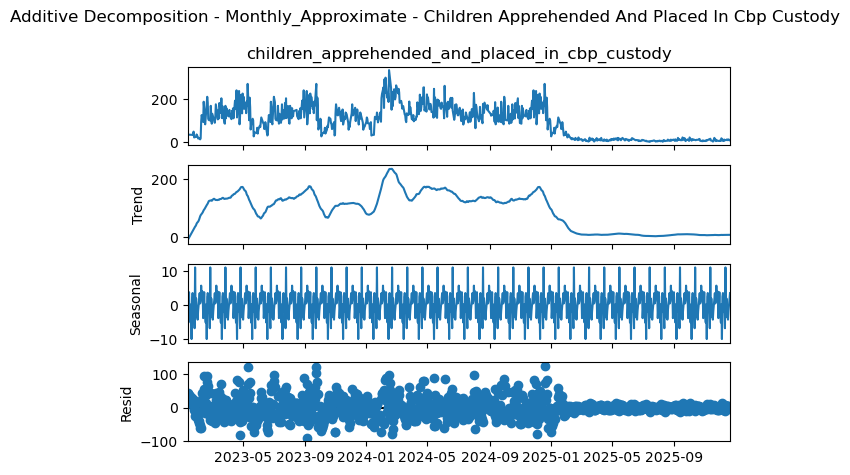

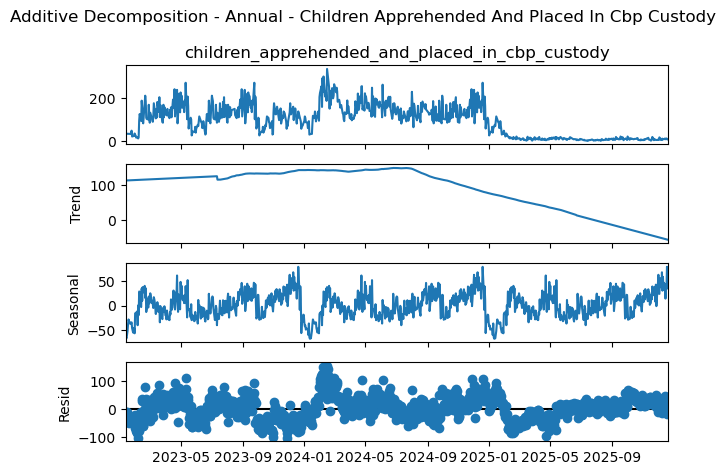

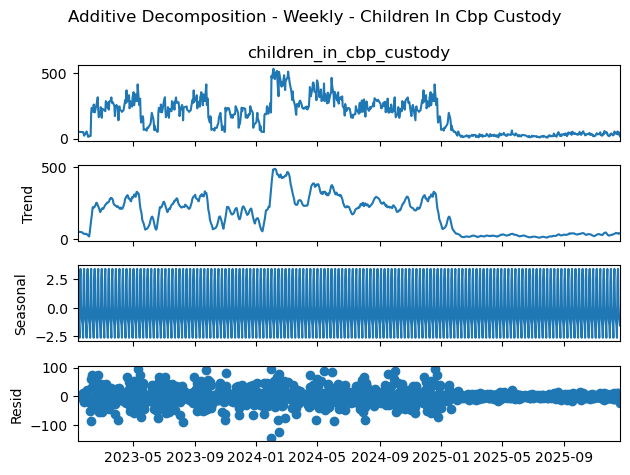

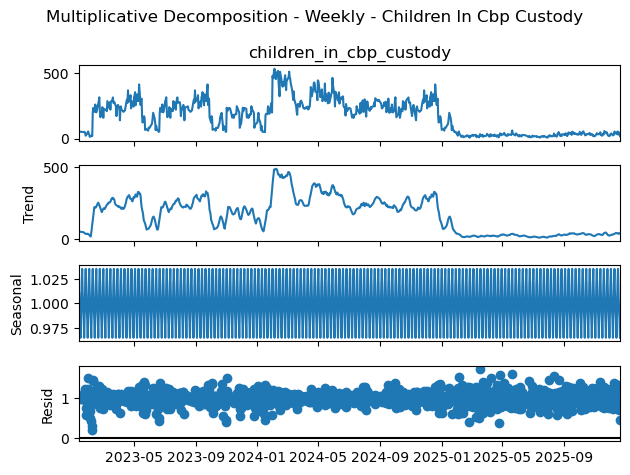

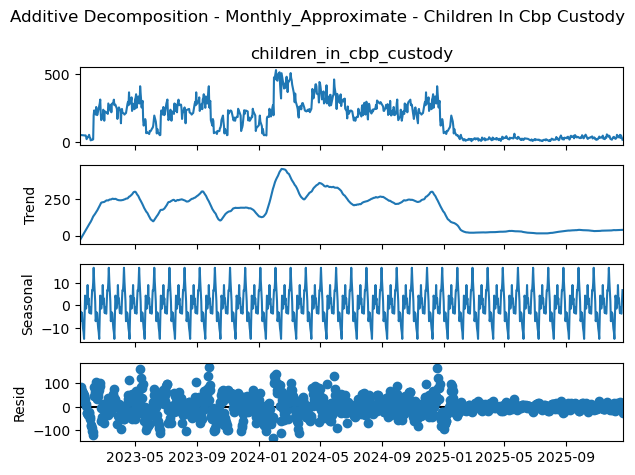

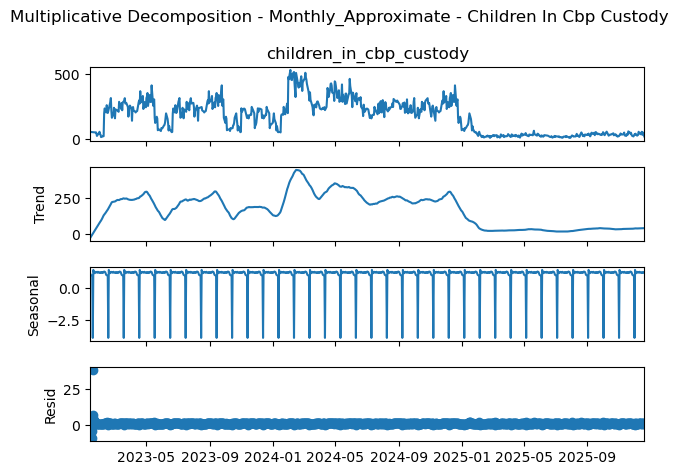

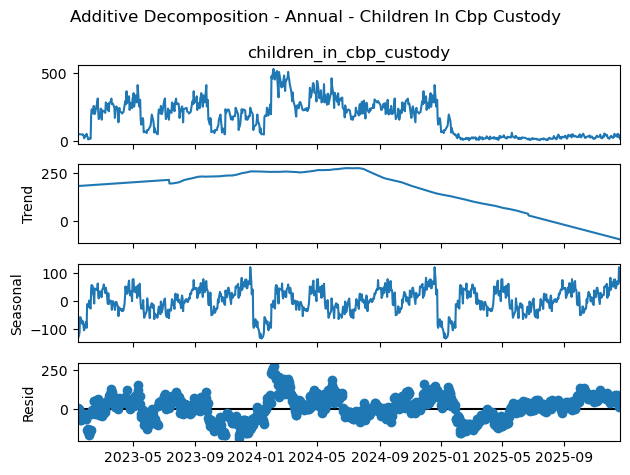

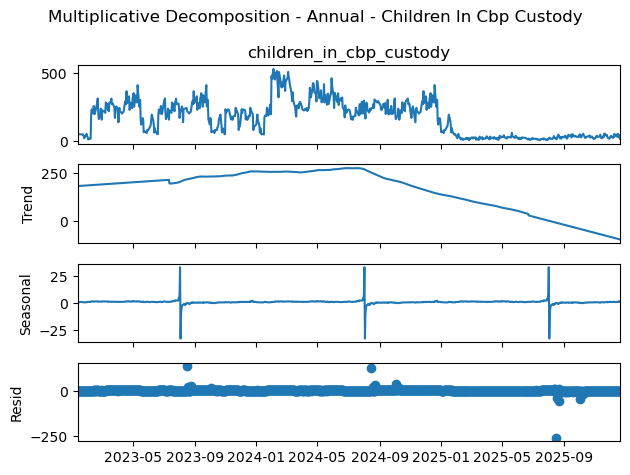

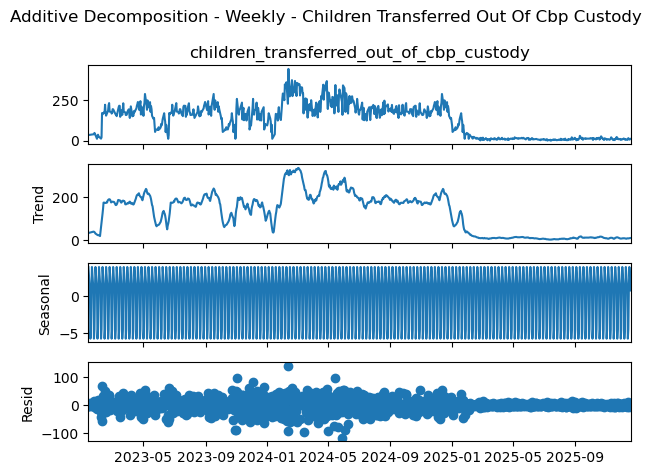

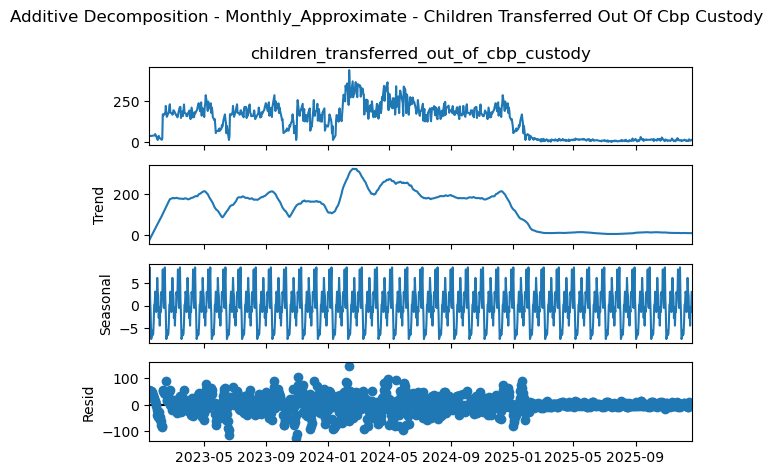

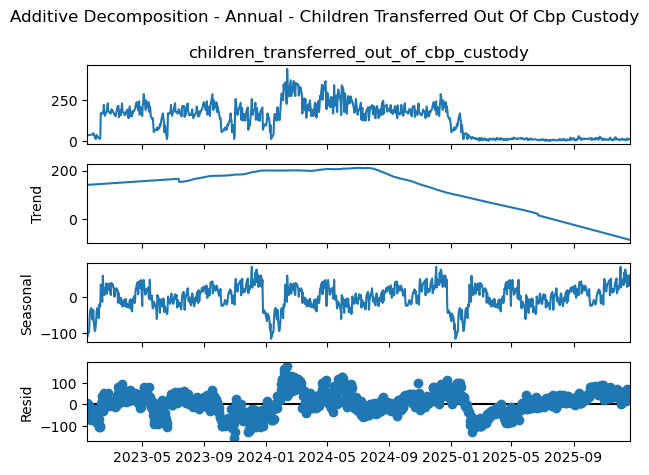

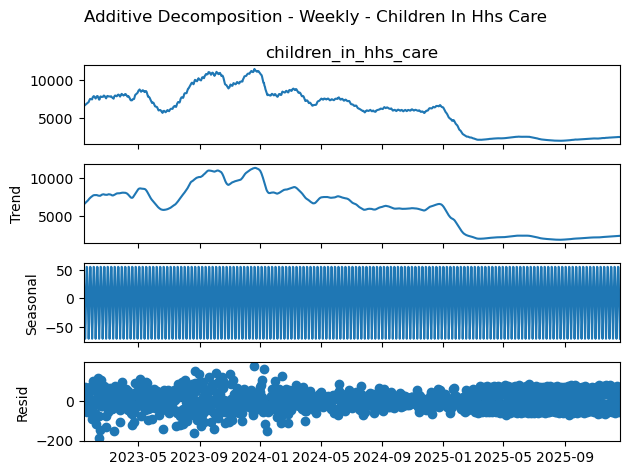

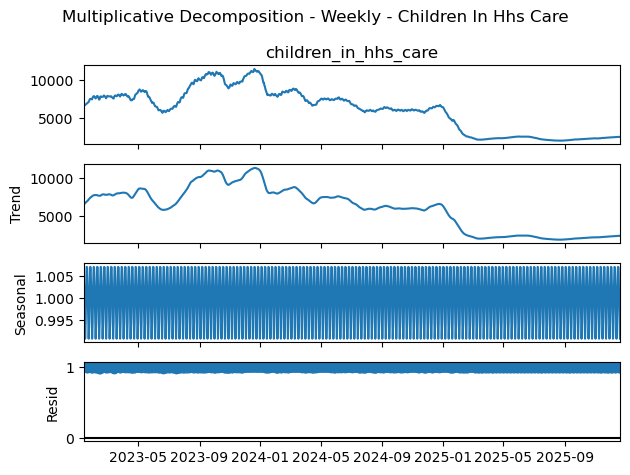

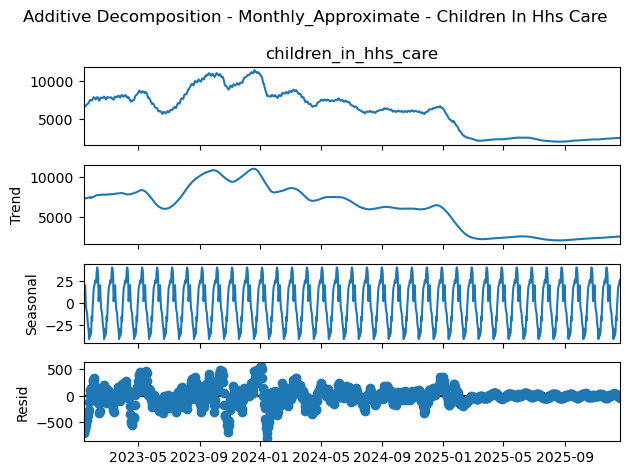

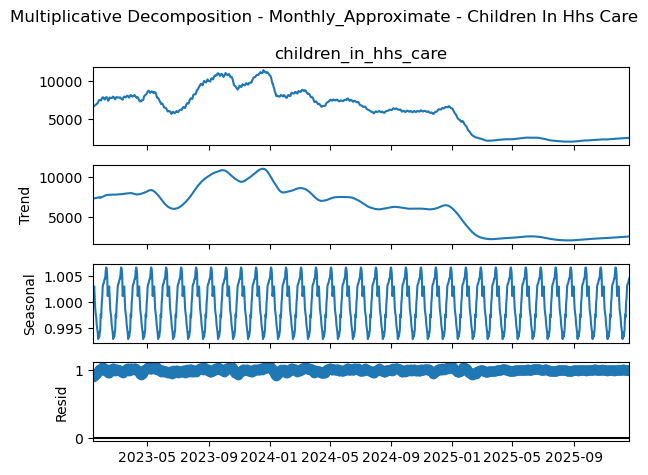

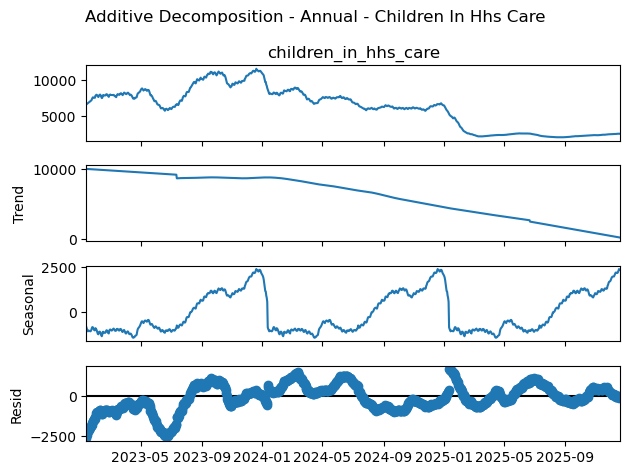

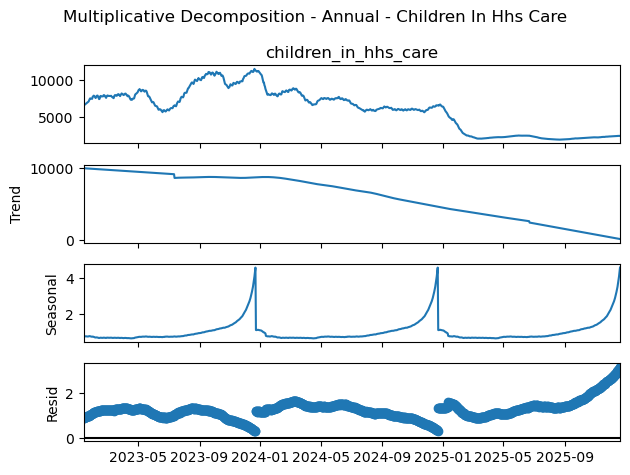

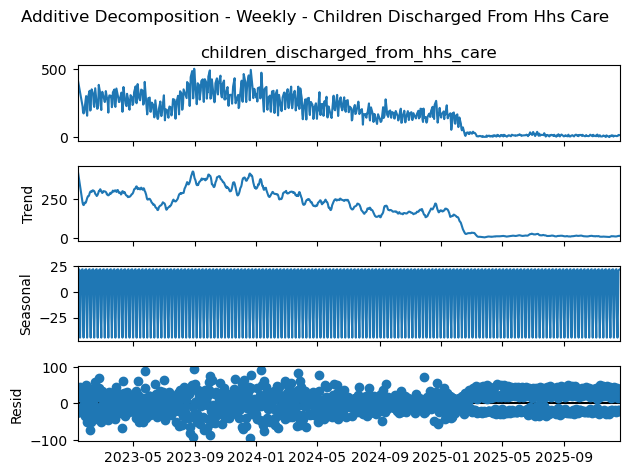

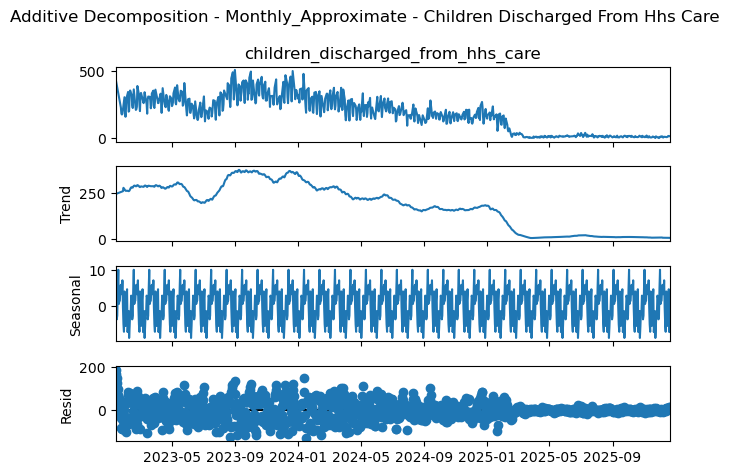

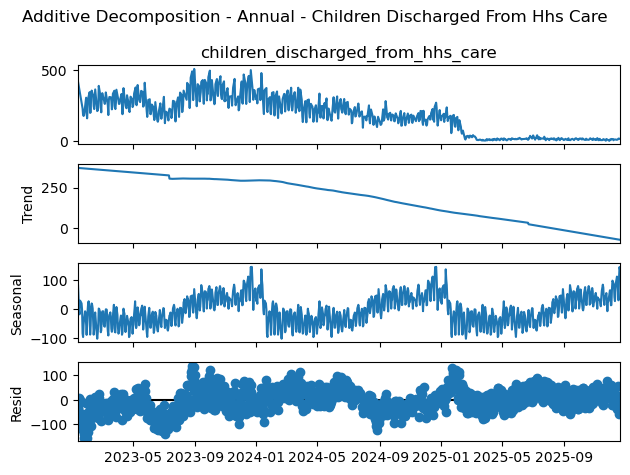


DECOMPOSITION RESULTS
                                      Variable  Seasonality_Period          Model                             Status  Residual_Standard_Deviation  Residual_Mean
children_apprehended_and_placed_in_cbp_custody              Weekly       Additive                          Completed                    23.514789       0.002045
children_apprehended_and_placed_in_cbp_custody              Weekly Multiplicative Skipped: non-positive observations                          NaN            NaN
children_apprehended_and_placed_in_cbp_custody Monthly_Approximate       Additive                          Completed                    28.923746       0.284220
children_apprehended_and_placed_in_cbp_custody Monthly_Approximate Multiplicative Skipped: non-positive observations                          NaN            NaN
children_apprehended_and_placed_in_cbp_custody              Annual       Additive                          Completed                    40.796267       3.201552
children_ap


ADF AND KPSS STATIONARITY RESULTS
                                      Variable  Original_Observed_Count  Diagnostic_Sample_Size  Interpolated_Values  ADF_Statistic  ADF_P_Value  ADF_Lags  ADF_Stationary_At_5_Percent  KPSS_Statistic  KPSS_P_Value  KPSS_Stationary_At_5_Percent              Combined_Interpretation
children_apprehended_and_placed_in_cbp_custody                      720                    1075                  355      -2.342815     0.158531        20                        False        2.672847          0.01                         False Both tests indicate non-stationarity
                       children_in_cbp_custody                      720                    1075                  355      -2.553497     0.102994        16                        False        2.300748          0.01                         False Both tests indicate non-stationarity
       children_transferred_out_of_cbp_custody                      720                    1075                  355      

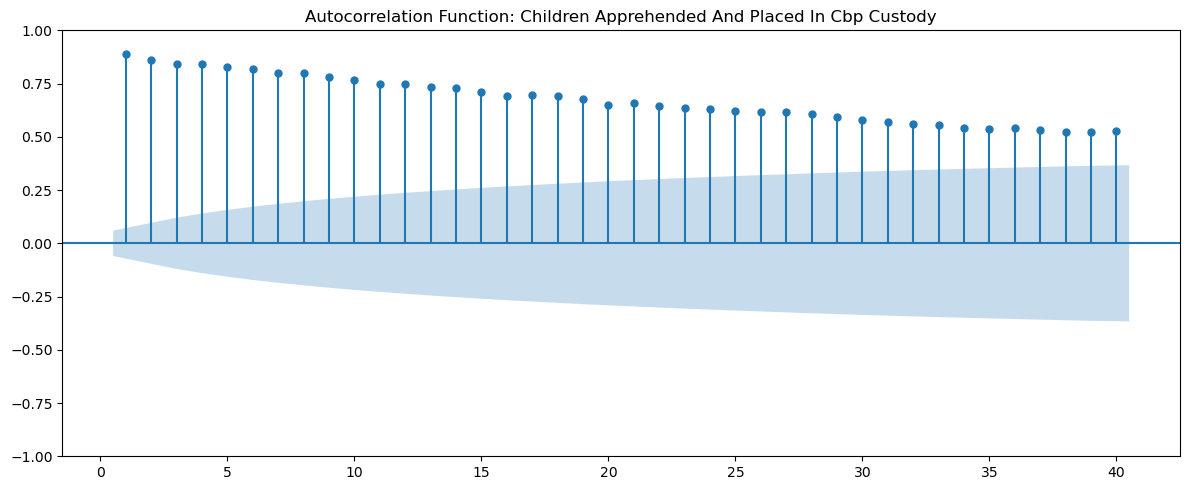

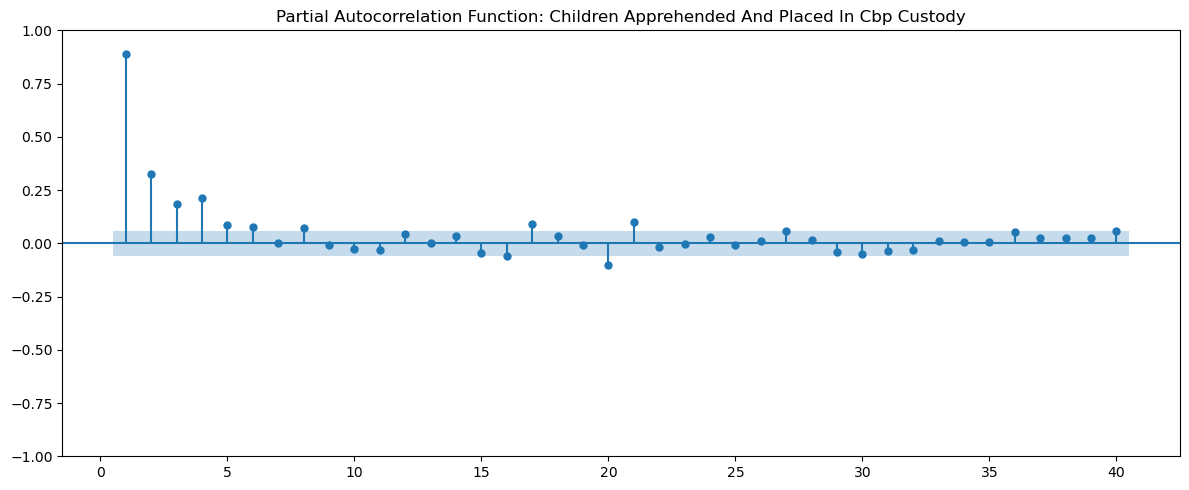

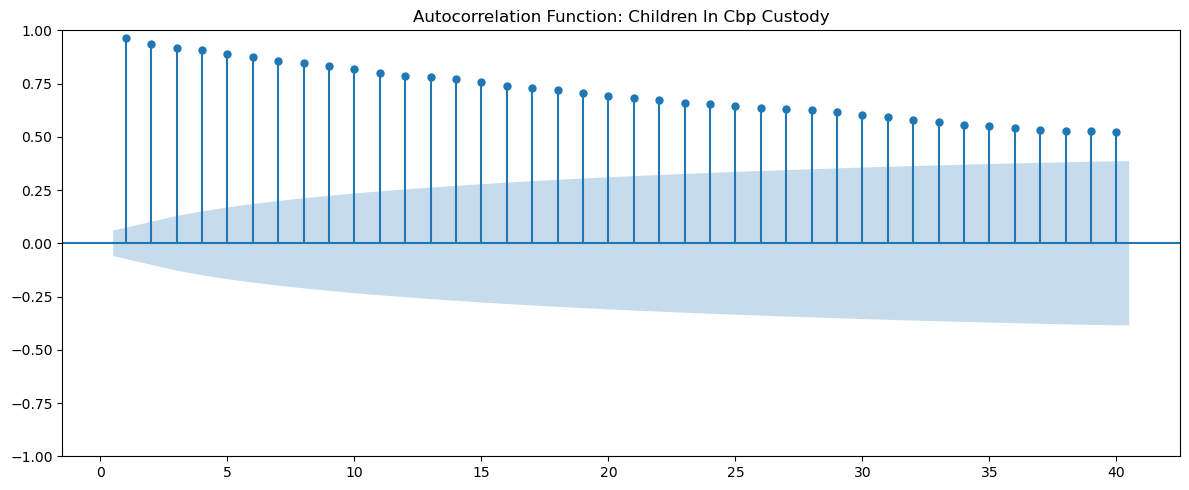

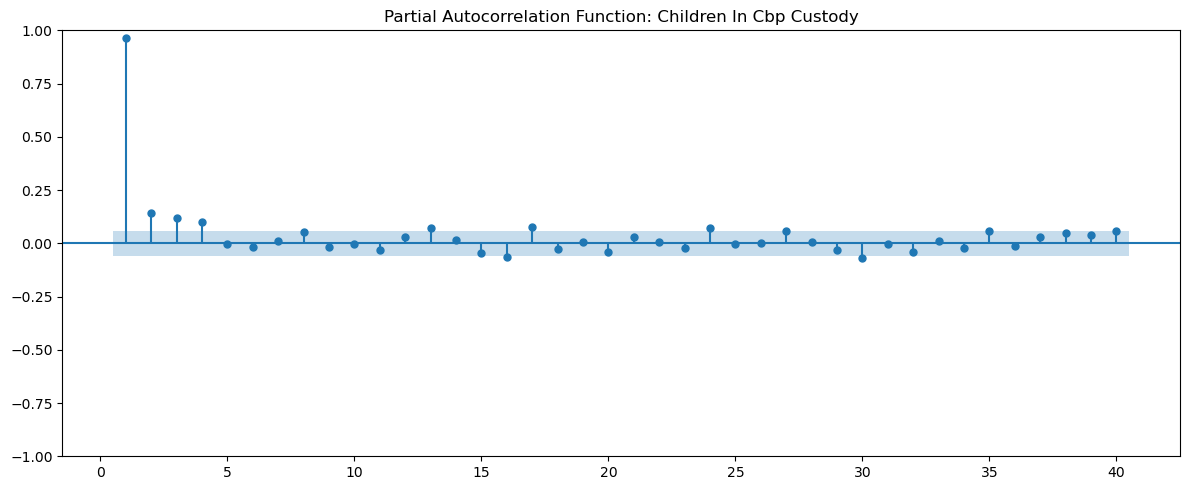

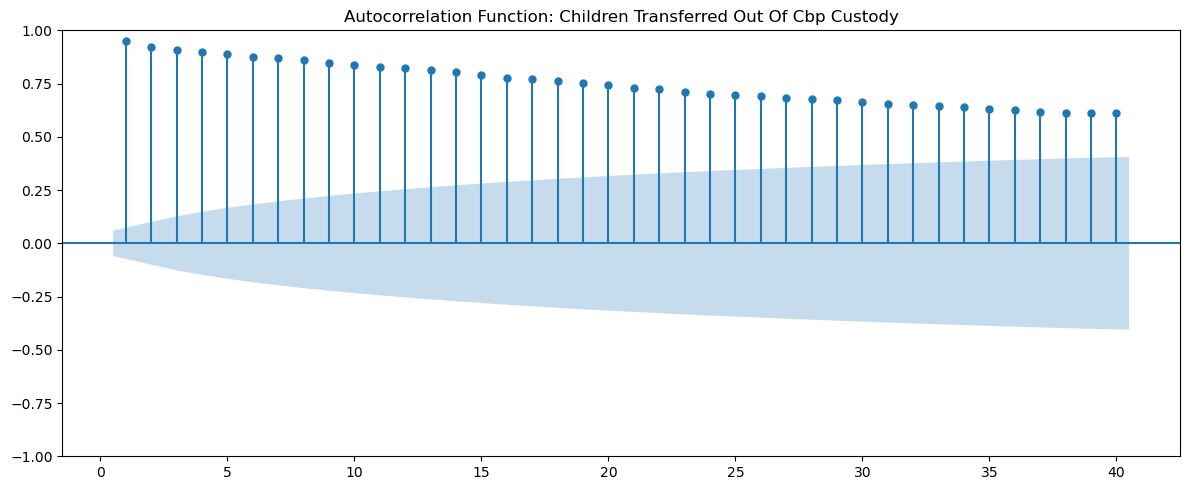

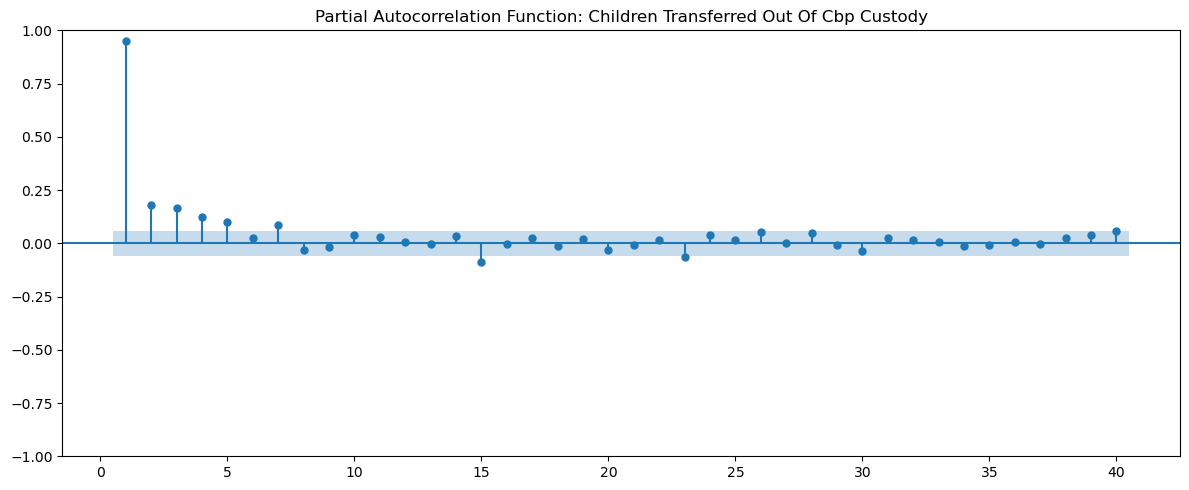

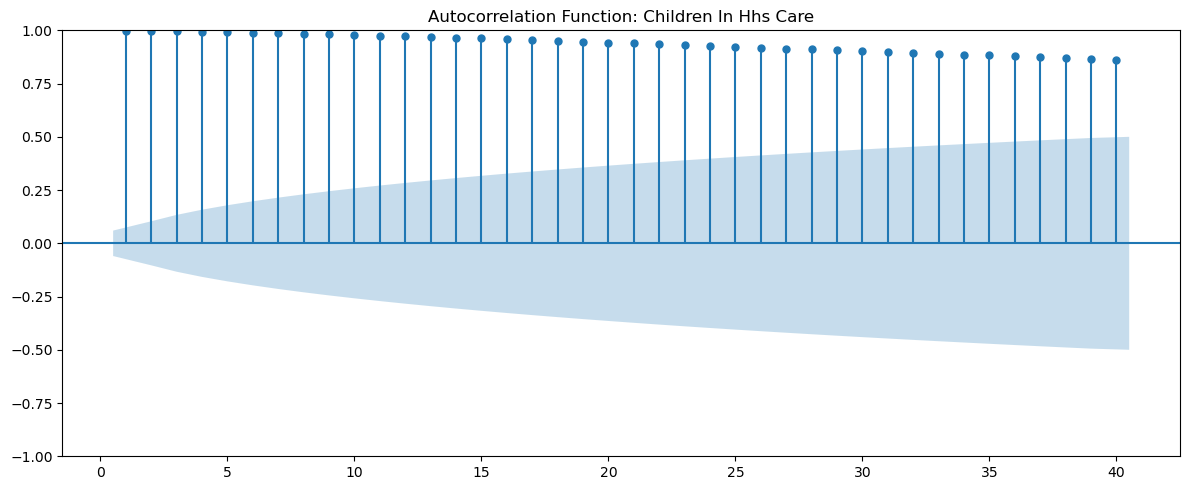

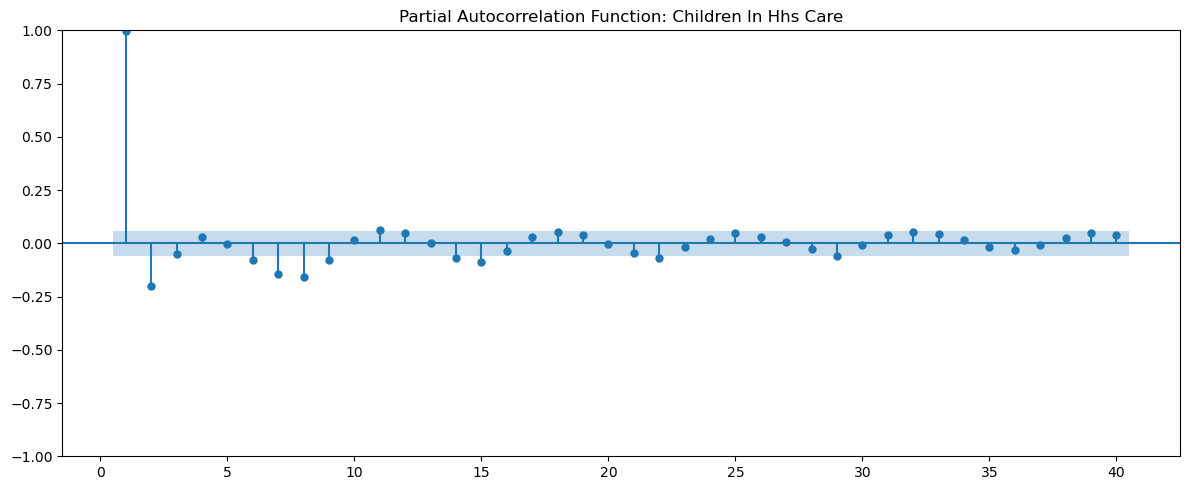

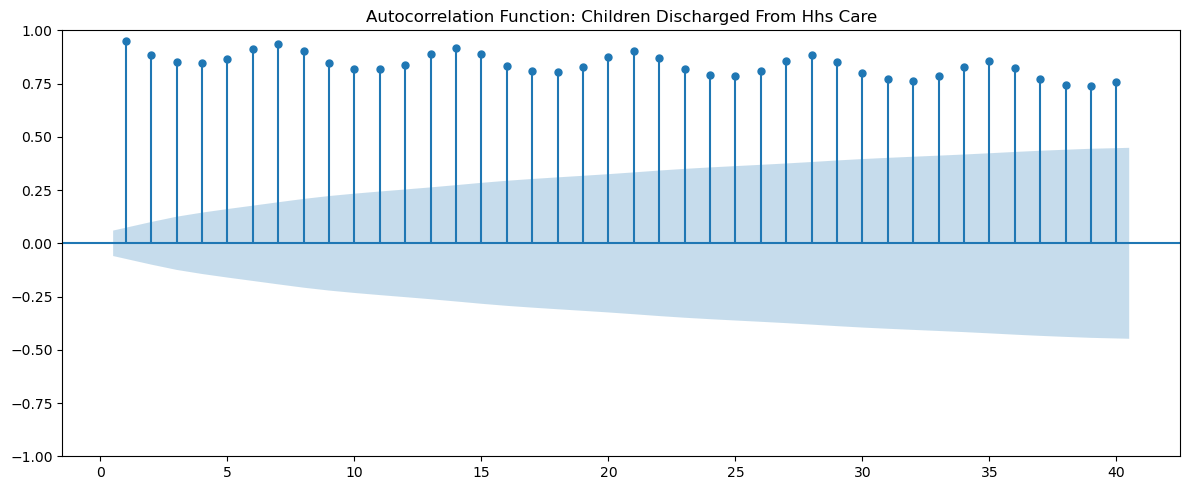

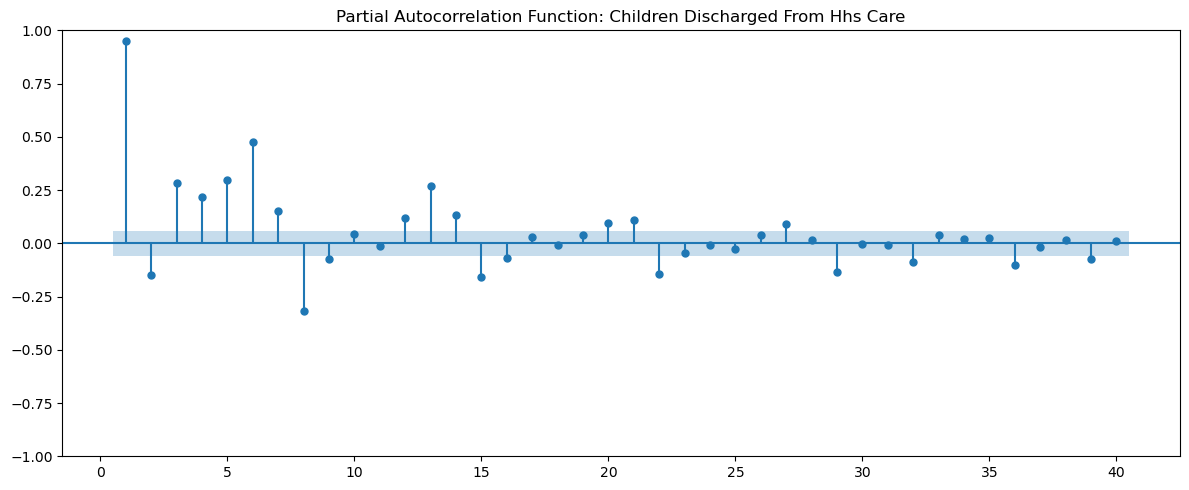


AUTOCORRELATION SUMMARY
                                      Variable  Lag_1_ACF  Lag_7_ACF  Lag_30_ACF  Maximum_Lag_Analyzed
children_apprehended_and_placed_in_cbp_custody     0.8909     0.8007      0.5791                    40
                       children_in_cbp_custody     0.9627     0.8565      0.6021                    40
       children_transferred_out_of_cbp_custody     0.9520     0.8711      0.6616                    40
                          children_in_hhs_care     0.9988     0.9874      0.9018                    40
             children_discharged_from_hhs_care     0.9483     0.9368      0.7980                    40


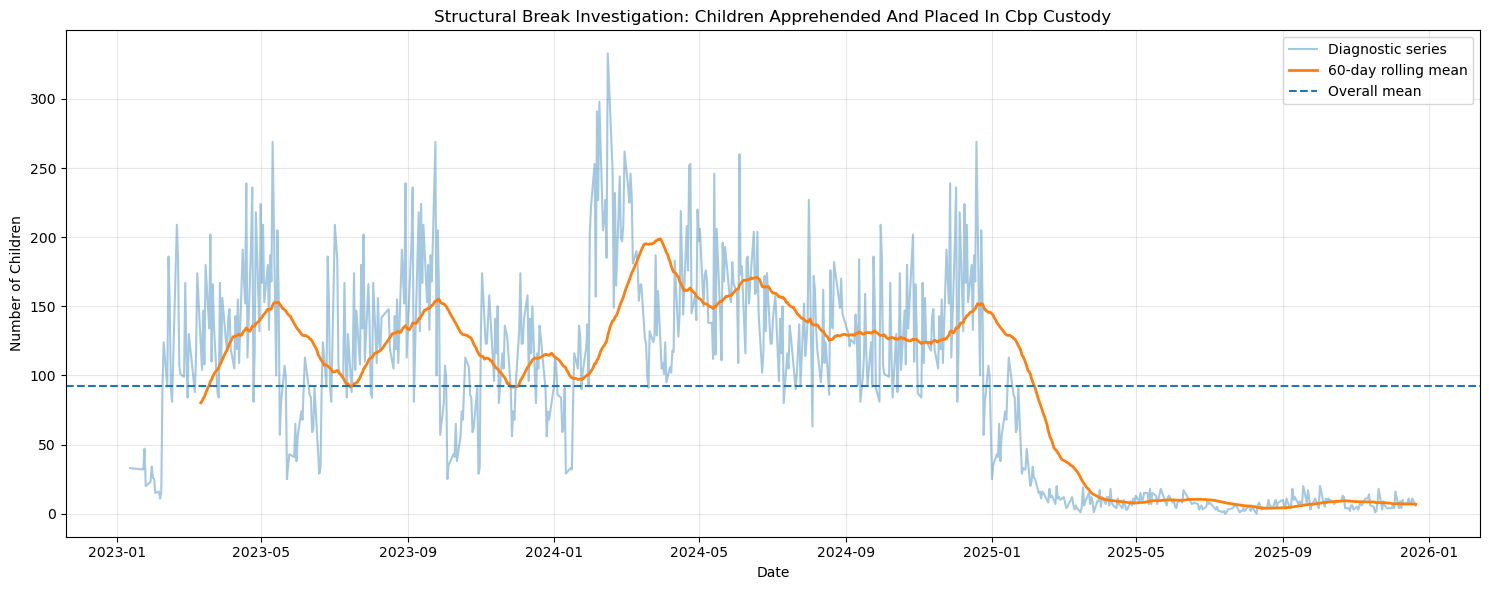

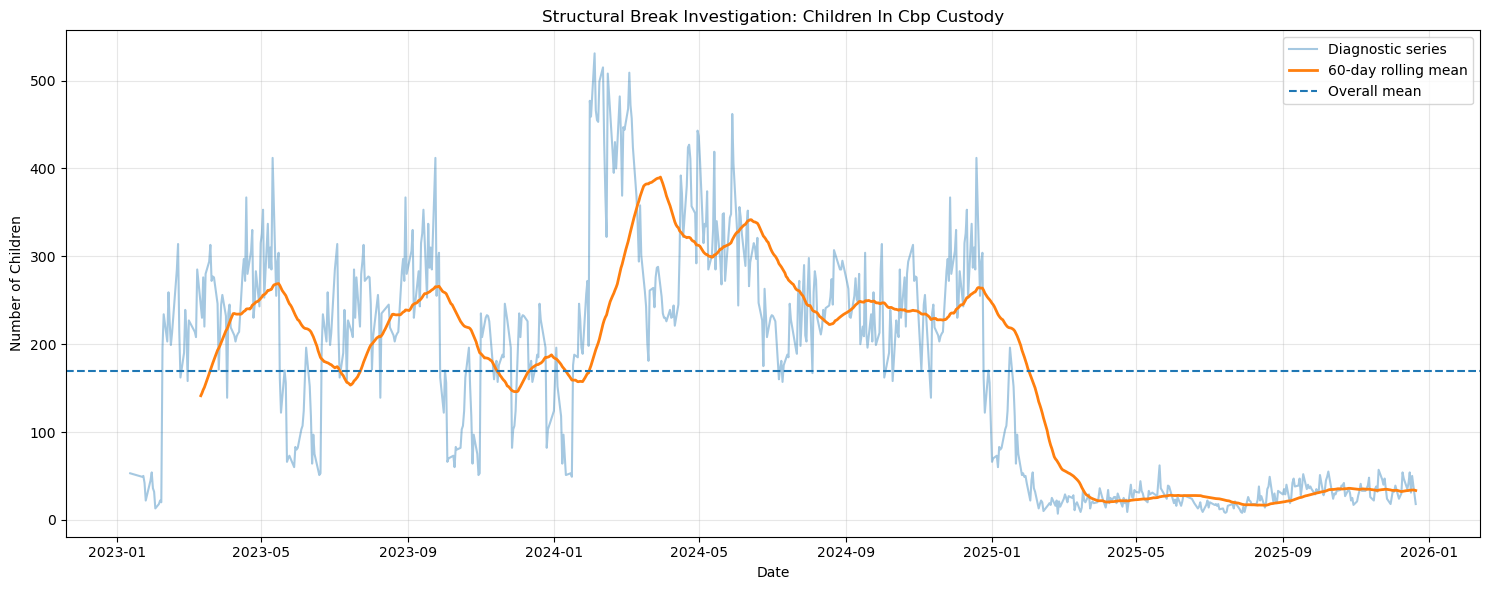

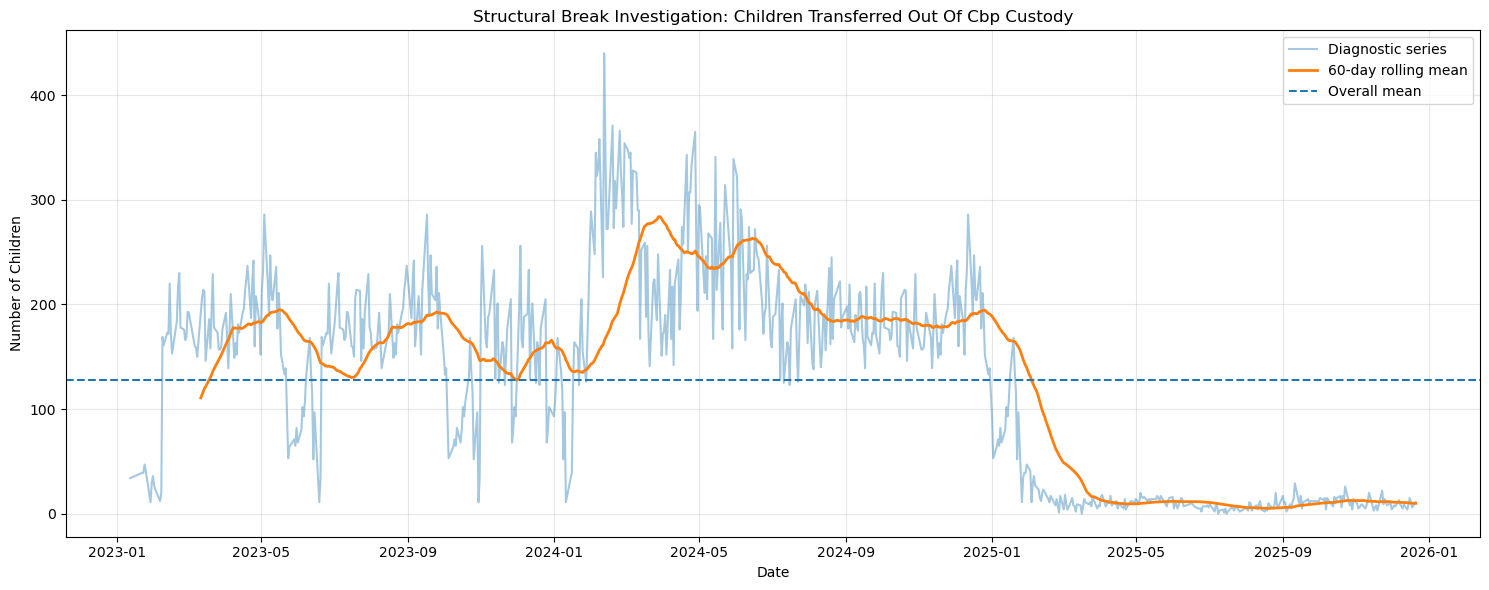

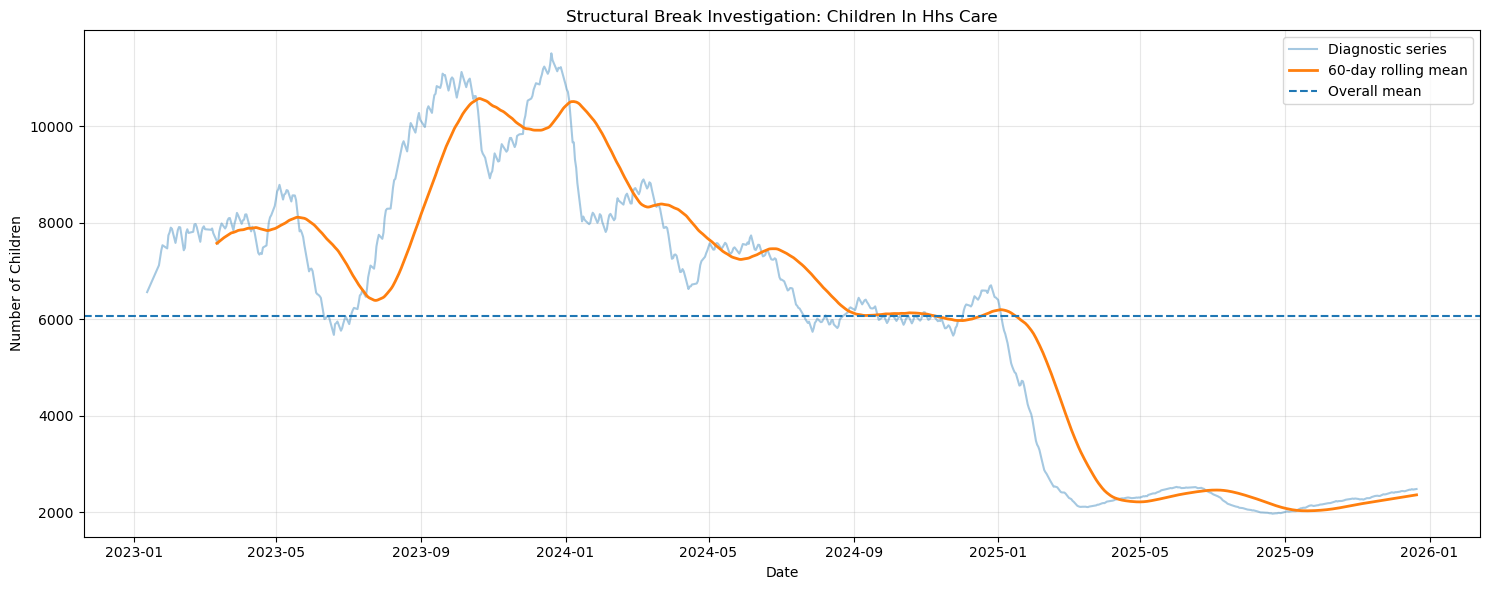

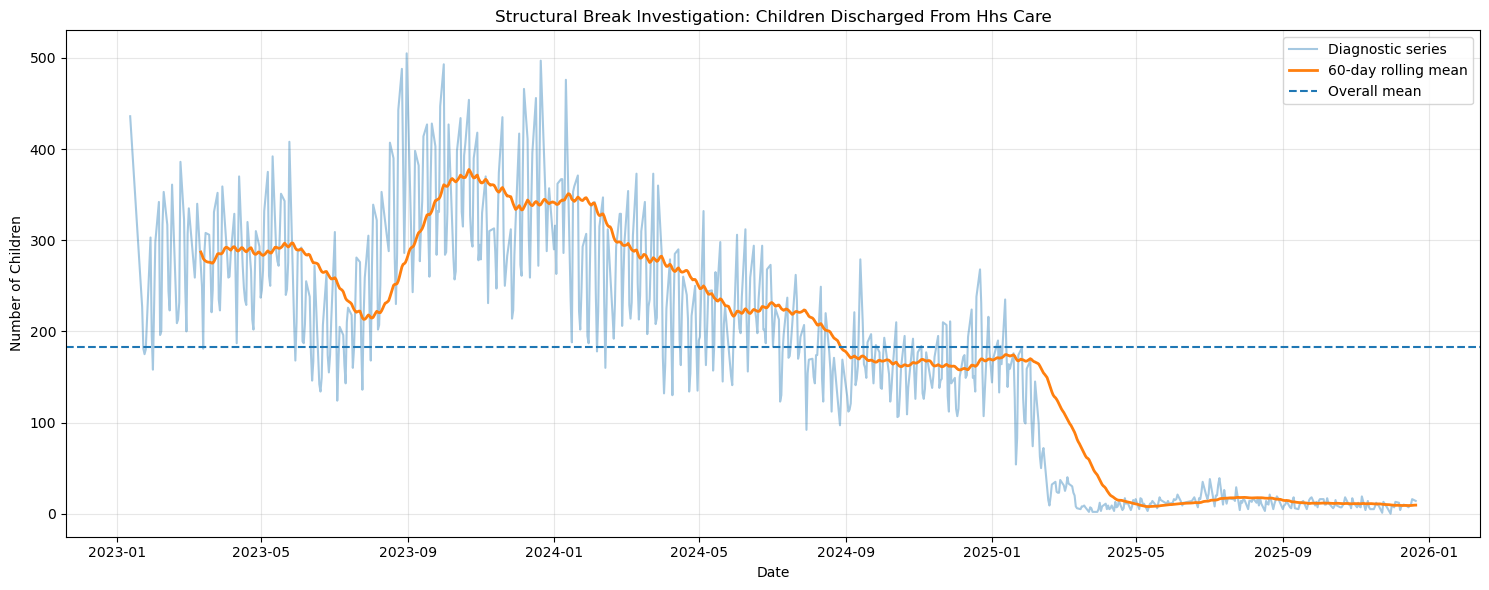

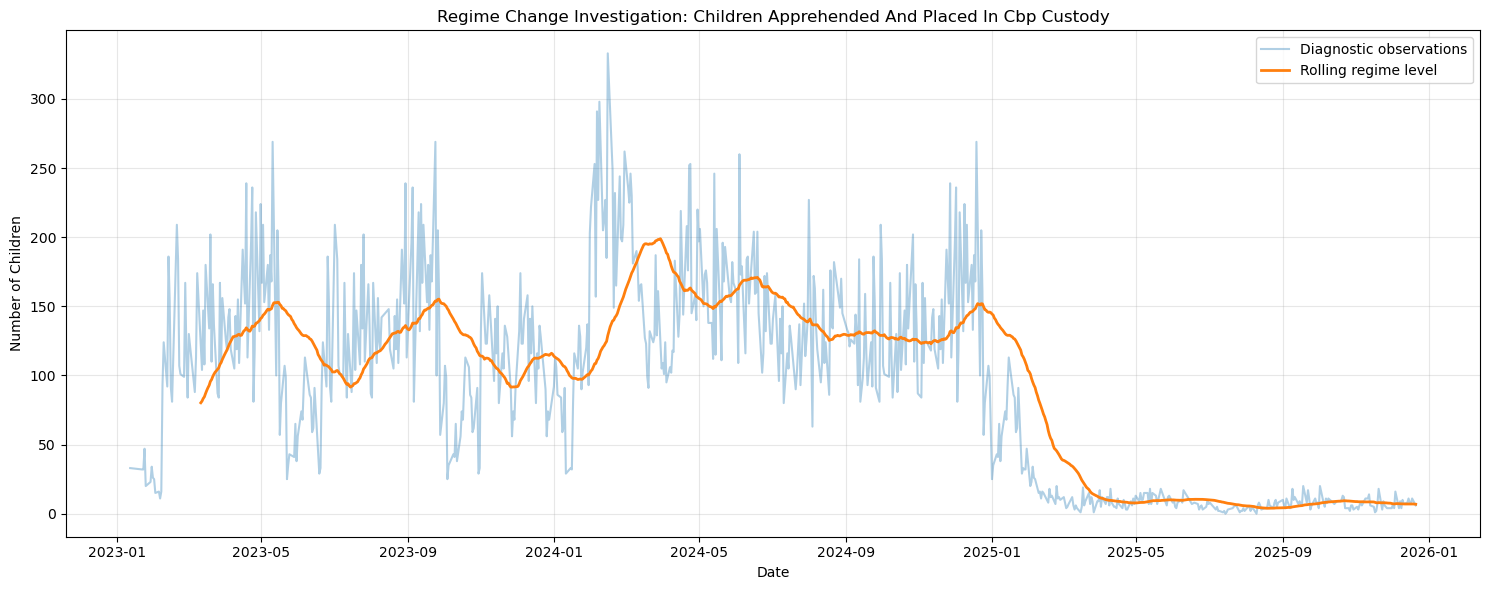

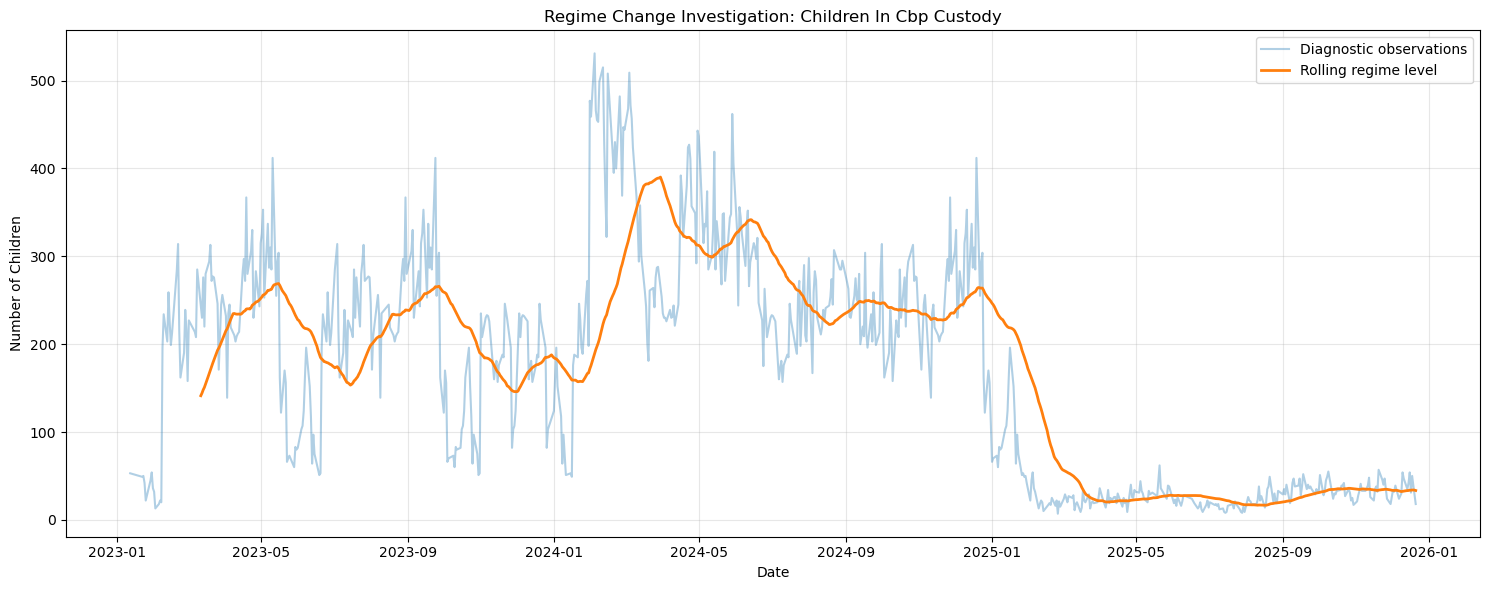

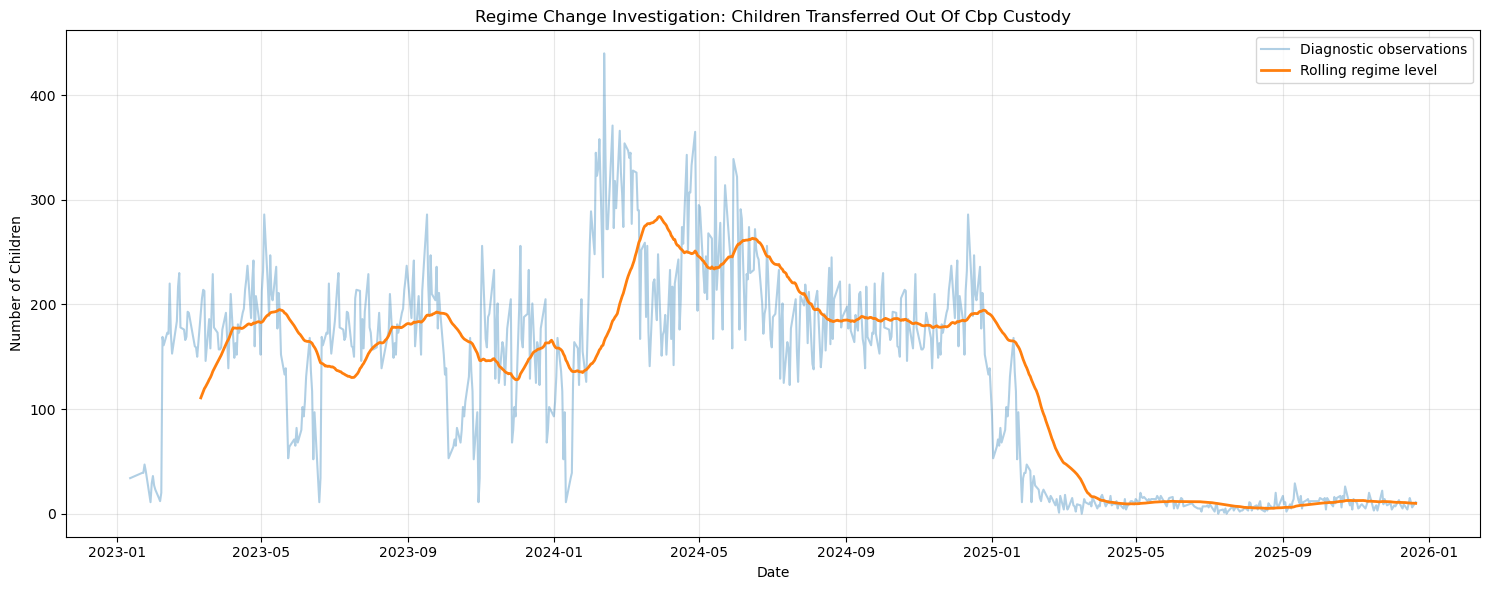

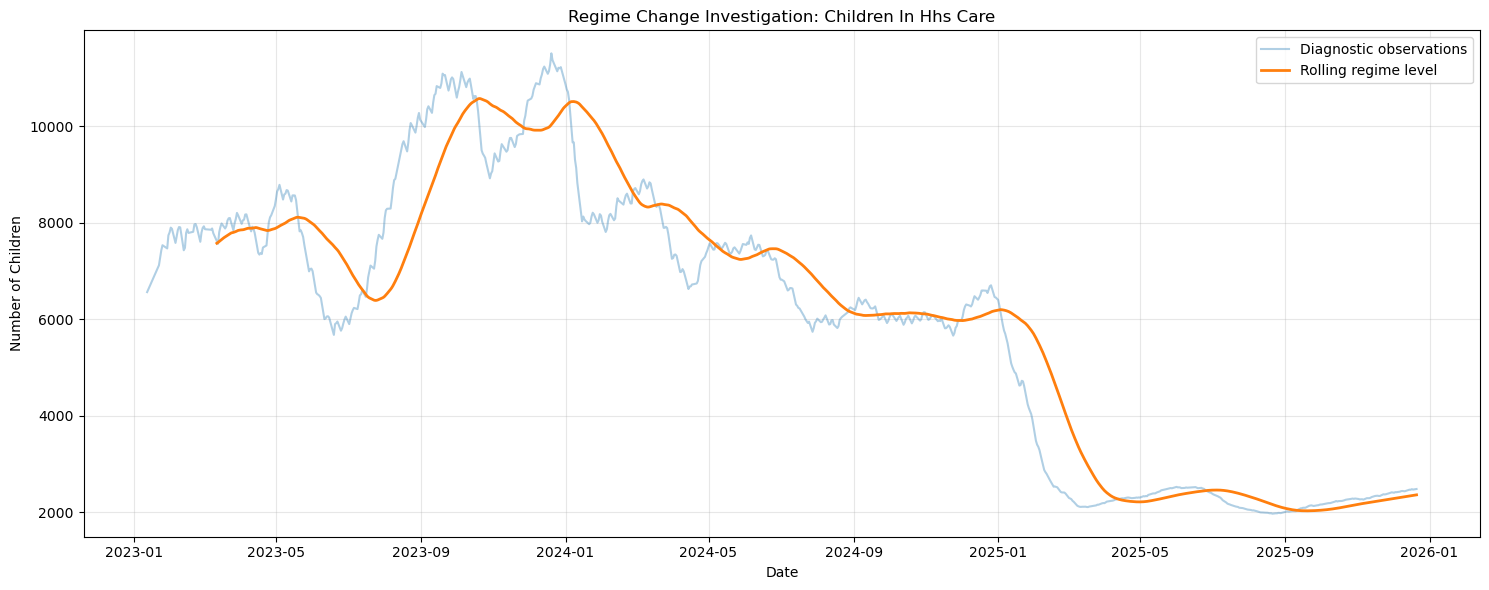

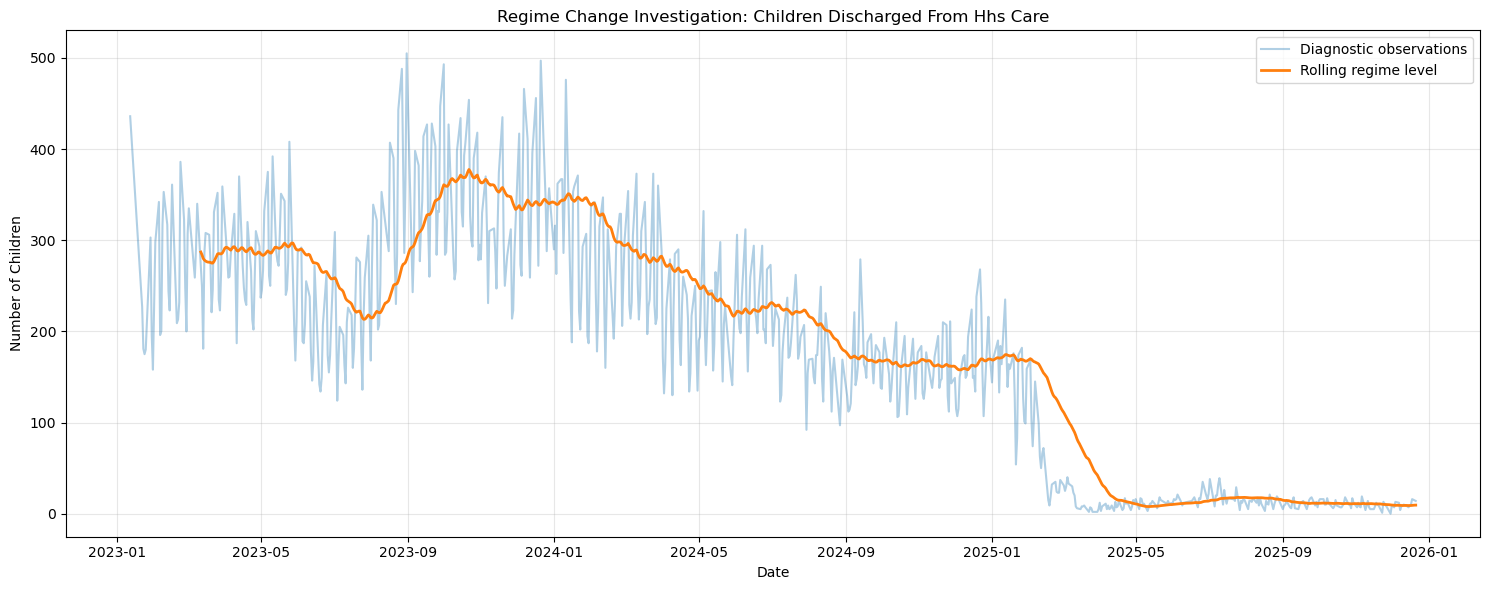


STATISTICAL ANALYTICAL FINDINGS
ADVANCED STATISTICAL TIME-SERIES ANALYSIS
Observation period: 2023-01-12 to 2025-12-21.
Observed records: 720.
Daily calendar length: 1075.
Missing calendar dates were preserved as missing observations.
Interpolation was used only for explicitly identified diagnostic analyses.

TREND ANALYSIS
children_apprehended_and_placed_in_cbp_custody: Decreasing; 30-day slope=-4.0878; R-squared=0.3315.
children_in_cbp_custody: Decreasing; 30-day slope=-6.6650; R-squared=0.2913.
children_transferred_out_of_cbp_custody: Decreasing; 30-day slope=-5.5693; R-squared=0.3429.
children_in_hhs_care: Decreasing; 30-day slope=-232.2064; R-squared=0.7034.
children_discharged_from_hhs_care: Decreasing; 30-day slope=-10.1555; R-squared=0.6834.

SEASONALITY TESTS
children_apprehended_and_placed_in_cbp_custody - Weekly: Kruskal-Wallis; p-value=0.678897392063219; Significant at 5%=False.
children_in_cbp_custody - Weekly: Kruskal-Wallis; p-value=0.8785976370816853; Significant at 5%

In [1]:

# ============================================================
# ADVANCED STATISTICAL TIME-SERIES ANALYSIS
# Project: Predictive Forecasting of Care Load & Placement Demand
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from pathlib import Path
from scipy import stats

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Project directory and dataset loading
# ------------------------------------------------------------

CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATASET_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "cleaned_care_data.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
ANALYSIS_DIR = OUTPUT_DIR / "statistical_analysis"
FIGURE_DIR = ANALYSIS_DIR / "figures"
REPORT_DIR = ANALYSIS_DIR / "reports"

for directory in [OUTPUT_DIR, ANALYSIS_DIR, FIGURE_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH)

DATE_COLUMN = "date"

VARIABLES = [
    "children_apprehended_and_placed_in_cbp_custody",
    "children_in_cbp_custody",
    "children_transferred_out_of_cbp_custody",
    "children_in_hhs_care",
    "children_discharged_from_hhs_care"
]

TARGET_VARIABLE = "children_in_hhs_care"

STOCK_VARIABLES = [
    "children_in_cbp_custody",
    "children_in_hhs_care"
]

FLOW_VARIABLES = [
    "children_apprehended_and_placed_in_cbp_custody",
    "children_transferred_out_of_cbp_custody",
    "children_discharged_from_hhs_care"
]

missing_columns = [
    col for col in [DATE_COLUMN] + VARIABLES
    if col not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns missing: {missing_columns}"
    )

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="coerce"
)

df = df.dropna(subset=[DATE_COLUMN]).copy()

for col in VARIABLES:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

df = df.sort_values(DATE_COLUMN).reset_index(drop=True)

if df[DATE_COLUMN].duplicated().any():
    raise ValueError(
        "Duplicate dates detected. Resolve them before analysis."
    )

minimum_date = df[DATE_COLUMN].min()
maximum_date = df[DATE_COLUMN].max()

calendar = pd.date_range(
    minimum_date,
    maximum_date,
    freq="D"
)

daily_df = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .reindex(calendar)
)

daily_df.index.name = DATE_COLUMN

observed_indicator = daily_df.notna()

print("=" * 70)
print("ADVANCED STATISTICAL TIME-SERIES ANALYSIS")
print("=" * 70)

print("Project directory:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("Observation period:", minimum_date.date(), "to", maximum_date.date())
print("Observed records:", len(df))
print("Calendar days:", len(calendar))
print("Missing calendar dates:", int((~calendar.isin(df[DATE_COLUMN])).sum()))

# ------------------------------------------------------------
# Statistical analysis configuration
# ------------------------------------------------------------

SEASONAL_PERIODS = {
    "Weekly": 7,
    "Monthly_Approximate": 30,
    "Annual": 365
}

MIN_DECOMPOSITION_CYCLES = 2

stationarity_results = []
seasonality_results = []
weekday_results = []
decomposition_results = []
autocorrelation_results = []
structural_break_results = []
regime_results = []
trend_results = []
annual_seasonality_results = []

# ------------------------------------------------------------
# Long-term and short-term trend analysis
# ------------------------------------------------------------

for variable in VARIABLES:

    series = daily_df[variable]

    observed_series = series.dropna()

    long_term_trend = series.rolling(
        window=180,
        min_periods=90
    ).mean()

    short_term_trend = series.rolling(
        window=30,
        min_periods=15
    ).mean()

    trend_df = pd.DataFrame({
        "Observed_Value": series,
        "Short_Term_Trend_30_Days": short_term_trend,
        "Long_Term_Trend_180_Days": long_term_trend
    })

    trend_df.to_csv(
        REPORT_DIR / f"trend_analysis_{variable}.csv"
    )

    if len(observed_series) >= 2:

        x = (
            observed_series.index -
            observed_series.index.min()
        ).days.to_numpy()

        slope, intercept = np.polyfit(
            x,
            observed_series.to_numpy(),
            1
        )

        fitted = slope * x + intercept

        ss_res = np.sum(
            (observed_series.to_numpy() - fitted) ** 2
        )

        ss_tot = np.sum(
            (observed_series.to_numpy() -
             observed_series.mean()) ** 2
        )

        r_squared = (
            1 - ss_res / ss_tot
            if ss_tot > 0 else np.nan
        )

    else:

        slope = np.nan
        intercept = np.nan
        r_squared = np.nan

    trend_results.append({
        "Variable": variable,
        "Long_Term_Trend_Slope_Per_Day": slope,
        "Trend_Slope_Per_30_Days": slope * 30,
        "Trend_R_Squared": r_squared,
        "Overall_Trend": (
            "Increasing" if slope > 0
            else "Decreasing" if slope < 0
            else "Undetermined"
        )
    })

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        series.index,
        series,
        alpha=0.35,
        linewidth=0.8,
        label="Observed values"
    )

    ax.plot(
        short_term_trend.index,
        short_term_trend,
        linewidth=1.5,
        label="30-day rolling trend"
    )

    ax.plot(
        long_term_trend.index,
        long_term_trend,
        linewidth=2,
        label="180-day rolling trend"
    )

    ax.set_title(
        f"Short-Term and Long-Term Trends: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Children")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"trend_analysis_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

trend_comparison = pd.DataFrame(trend_results)

trend_comparison.to_csv(
    REPORT_DIR / "long_term_and_short_term_trends.csv",
    index=False
)

print("\nLONG-TERM AND SHORT-TERM TREND ANALYSIS")
print(trend_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# Weekly seasonality analysis
# ------------------------------------------------------------

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

for variable in VARIABLES:

    weekday_data = df[
        [DATE_COLUMN, variable]
    ].dropna().copy()

    weekday_data["Weekday"] = (
        weekday_data[DATE_COLUMN].dt.day_name()
    )

    weekday_summary = (
        weekday_data.groupby("Weekday")[variable]
        .agg(["count", "mean", "median", "std"])
        .reindex(weekday_names)
    )

    weekday_summary.to_csv(
        REPORT_DIR / f"weekly_seasonality_{variable}.csv"
    )

    grouped_values = [
        weekday_data.loc[
            weekday_data["Weekday"] == day,
            variable
        ].dropna().values
        for day in weekday_names
    ]

    valid_groups = [
        group for group in grouped_values
        if len(group) >= 2
    ]

    if len(valid_groups) >= 2:

        statistic, p_value = stats.kruskal(
            *valid_groups
        )

    else:

        statistic, p_value = np.nan, np.nan

    seasonality_results.append({
        "Variable": variable,
        "Seasonality_Type": "Weekly",
        "Test": "Kruskal-Wallis",
        "Statistic": statistic,
        "P_Value": p_value,
        "Significant_At_5_Percent": (
            p_value < 0.05
            if pd.notna(p_value) else False
        )
    })

    fig, ax = plt.subplots(figsize=(11, 6))

    sns.boxplot(
        data=weekday_data,
        x="Weekday",
        y=variable,
        order=weekday_names,
        ax=ax
    )

    ax.set_title(
        f"Weekly Seasonality: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Day of Week")
    ax.set_ylabel("Number of Children")
    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"weekly_seasonality_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Weekday and weekend comparison
# ------------------------------------------------------------

for variable in VARIABLES:

    weekend_data = df[
        [DATE_COLUMN, variable]
    ].dropna().copy()

    weekend_data["Day_Type"] = np.where(
        weekend_data[DATE_COLUMN].dt.dayofweek >= 5,
        "Weekend",
        "Weekday"
    )

    weekday_values = weekend_data.loc[
        weekend_data["Day_Type"] == "Weekday",
        variable
    ]

    weekend_values = weekend_data.loc[
        weekend_data["Day_Type"] == "Weekend",
        variable
    ]

    if len(weekday_values) >= 2 and len(weekend_values) >= 2:

        statistic, p_value = stats.mannwhitneyu(
            weekday_values,
            weekend_values,
            alternative="two-sided"
        )

    else:

        statistic, p_value = np.nan, np.nan

    weekday_results.append({
        "Variable": variable,
        "Weekday_Count": len(weekday_values),
        "Weekend_Count": len(weekend_values),
        "Weekday_Mean": weekday_values.mean(),
        "Weekend_Mean": weekend_values.mean(),
        "Weekday_Median": weekday_values.median(),
        "Weekend_Median": weekend_values.median(),
        "Mann_Whitney_Statistic": statistic,
        "P_Value": p_value,
        "Significant_At_5_Percent": (
            p_value < 0.05
            if pd.notna(p_value) else False
        )
    })

weekday_comparison = pd.DataFrame(weekday_results)

weekday_comparison.to_csv(
    REPORT_DIR / "weekday_weekend_comparison.csv",
    index=False
)

print("\nWEEKDAY AND WEEKEND COMPARISON")
print(weekday_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# Monthly seasonality analysis
# ------------------------------------------------------------

for variable in VARIABLES:

    monthly_data = df[
        [DATE_COLUMN, variable]
    ].dropna().copy()

    monthly_data["Month"] = (
        monthly_data[DATE_COLUMN].dt.month
    )

    monthly_summary = (
        monthly_data.groupby("Month")[variable]
        .agg(["count", "mean", "median", "std"])
    )

    monthly_summary.to_csv(
        REPORT_DIR / f"monthly_seasonality_{variable}.csv"
    )

    monthly_groups = [
        monthly_data.loc[
            monthly_data["Month"] == month,
            variable
        ].values
        for month in range(1, 13)
    ]

    valid_groups = [
        group for group in monthly_groups
        if len(group) >= 2
    ]

    if len(valid_groups) >= 2:

        statistic, p_value = stats.kruskal(
            *valid_groups
        )

    else:

        statistic, p_value = np.nan, np.nan

    seasonality_results.append({
        "Variable": variable,
        "Seasonality_Type": "Monthly",
        "Test": "Kruskal-Wallis",
        "Statistic": statistic,
        "P_Value": p_value,
        "Significant_At_5_Percent": (
            p_value < 0.05
            if pd.notna(p_value) else False
        )
    })

    fig, ax = plt.subplots(figsize=(11, 6))

    sns.boxplot(
        data=monthly_data,
        x="Month",
        y=variable,
        ax=ax
    )

    ax.set_title(
        f"Monthly Seasonality: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Calendar Month")
    ax.set_ylabel("Number of Children")

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"monthly_seasonality_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Annual seasonality investigation
# ------------------------------------------------------------

for variable in VARIABLES:

    annual_data = (
        df.set_index(DATE_COLUMN)[variable]
        .resample("YE")
        .agg(["mean", "median", "std", "count"])
    )

    annual_data.index = annual_data.index.year

    annual_data.index.name = "Year"

    annual_data.to_csv(
        REPORT_DIR / f"annual_seasonality_{variable}.csv"
    )

    annual_seasonality_results.append({
        "Variable": variable,
        "Number_Of_Years": len(annual_data),
        "Annual_Mean_Range": (
            annual_data["mean"].max() -
            annual_data["mean"].min()
            if not annual_data.empty else np.nan
        ),
        "Interpretation": (
            "Annual observations summarized; insufficient "
            "independent annual cycles for reliable annual "
            "seasonality inference."
            if len(annual_data) < 3
            else
            "Annual changes can be compared, but repeated "
            "yearly seasonality requires further validation."
        )
    })

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        annual_data.index,
        annual_data["mean"],
        marker="o"
    )

    ax.set_title(
        f"Annual Average: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("Annual Mean")
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"annual_seasonality_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

annual_seasonality_df = pd.DataFrame(
    annual_seasonality_results
)

annual_seasonality_df.to_csv(
    REPORT_DIR / "annual_seasonality_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Additive and multiplicative decomposition
# ------------------------------------------------------------

for variable in VARIABLES:

    observed_series = daily_df[variable]

    # Diagnostic interpolation only, not replacement in source data.
    diagnostic_series = observed_series.interpolate(
        method="time",
        limit_area="inside"
    )

    for season_name, period in [
        ("Weekly", 7),
        ("Monthly_Approximate", 30),
        ("Annual", 365)
    ]:

        if len(diagnostic_series.dropna()) < (
            MIN_DECOMPOSITION_CYCLES * period
        ):

            print(
                f"Skipping {season_name} decomposition for "
                f"{variable}: insufficient observations."
            )

            continue

        # Exclude leading and trailing missing dates
        complete_series = diagnostic_series.dropna()

        # Verify continuous daily index
        if not complete_series.index.to_series().diff().dropna().eq(
            pd.Timedelta(days=1)
        ).all():

            continue

        # Additive decomposition
        try:

            additive_result = seasonal_decompose(
                complete_series,
                model="additive",
                period=period,
                extrapolate_trend="freq"
            )

            additive_components = pd.DataFrame({
                "Observed": complete_series,
                "Trend": additive_result.trend,
                "Seasonal": additive_result.seasonal,
                "Residual": additive_result.resid
            })

            additive_components.to_csv(
                REPORT_DIR /
                f"additive_decomposition_{season_name}_{variable}.csv"
            )

            additive_result.plot()

            plt.suptitle(
                f"Additive Decomposition - {season_name} - "
                f"{variable.replace('_', ' ').title()}"
            )

            plt.tight_layout()

            plt.savefig(
                FIGURE_DIR /
                f"additive_decomposition_{season_name}_{variable}.png",
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            decomposition_results.append({
                "Variable": variable,
                "Seasonality_Period": season_name,
                "Model": "Additive",
                "Status": "Completed",
                "Residual_Standard_Deviation": (
                    additive_result.resid.std()
                ),
                "Residual_Mean": additive_result.resid.mean()
            })

        except Exception as error:

            decomposition_results.append({
                "Variable": variable,
                "Seasonality_Period": season_name,
                "Model": "Additive",
                "Status": str(error),
                "Residual_Standard_Deviation": np.nan,
                "Residual_Mean": np.nan
            })

        # Multiplicative decomposition requires positive values
        try:

            if (complete_series <= 0).any():

                decomposition_results.append({
                    "Variable": variable,
                    "Seasonality_Period": season_name,
                    "Model": "Multiplicative",
                    "Status": "Skipped: non-positive observations",
                    "Residual_Standard_Deviation": np.nan,
                    "Residual_Mean": np.nan
                })

                continue

            multiplicative_result = seasonal_decompose(
                complete_series,
                model="multiplicative",
                period=period,
                extrapolate_trend="freq"
            )

            multiplicative_components = pd.DataFrame({
                "Observed": complete_series,
                "Trend": multiplicative_result.trend,
                "Seasonal": multiplicative_result.seasonal,
                "Residual": multiplicative_result.resid
            })

            multiplicative_components.to_csv(
                REPORT_DIR /
                f"multiplicative_decomposition_{season_name}_{variable}.csv"
            )

            multiplicative_result.plot()

            plt.suptitle(
                f"Multiplicative Decomposition - {season_name} - "
                f"{variable.replace('_', ' ').title()}"
            )

            plt.tight_layout()

            plt.savefig(
                FIGURE_DIR /
                f"multiplicative_decomposition_{season_name}_{variable}.png",
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            decomposition_results.append({
                "Variable": variable,
                "Seasonality_Period": season_name,
                "Model": "Multiplicative",
                "Status": "Completed",
                "Residual_Standard_Deviation": (
                    multiplicative_result.resid.std()
                ),
                "Residual_Mean": multiplicative_result.resid.mean()
            })

        except Exception as error:

            decomposition_results.append({
                "Variable": variable,
                "Seasonality_Period": season_name,
                "Model": "Multiplicative",
                "Status": str(error),
                "Residual_Standard_Deviation": np.nan,
                "Residual_Mean": np.nan
            })

decomposition_df = pd.DataFrame(
    decomposition_results
)

decomposition_df.to_csv(
    REPORT_DIR / "decomposition_comparison.csv",
    index=False
)

print("\nDECOMPOSITION RESULTS")
print(decomposition_df.to_string(index=False))

# ------------------------------------------------------------
# Stationarity testing using ADF and KPSS
# ------------------------------------------------------------

for variable in VARIABLES:

    original_series = daily_df[variable]

    # Use internal time interpolation only for statistical diagnostics.
    # Original observations and missing-date indicators remain unchanged.
    test_series = original_series.interpolate(
        method="time",
        limit_area="inside"
    ).dropna()

    result = {
        "Variable": variable,
        "Original_Observed_Count": int(original_series.notna().sum()),
        "Diagnostic_Sample_Size": len(test_series),
        "Interpolated_Values": int(
            test_series.notna().sum() -
            original_series.notna().sum()
        ),
        "ADF_Statistic": np.nan,
        "ADF_P_Value": np.nan,
        "ADF_Lags": np.nan,
        "ADF_Stationary_At_5_Percent": False,
        "KPSS_Statistic": np.nan,
        "KPSS_P_Value": np.nan,
        "KPSS_Stationary_At_5_Percent": False,
        "Combined_Interpretation": "Undetermined"
    }

    if len(test_series) >= 30:

        try:

            adf_result = adfuller(
                test_series,
                autolag="AIC"
            )

            result["ADF_Statistic"] = adf_result[0]
            result["ADF_P_Value"] = adf_result[1]
            result["ADF_Lags"] = adf_result[2]

            result["ADF_Stationary_At_5_Percent"] = (
                adf_result[1] < 0.05
            )

        except Exception as error:
            print("ADF error:", variable, error)

        try:

            kpss_result = kpss(
                test_series,
                regression="c",
                nlags="auto"
            )

            result["KPSS_Statistic"] = kpss_result[0]
            result["KPSS_P_Value"] = kpss_result[1]

            result["KPSS_Stationary_At_5_Percent"] = (
                kpss_result[1] > 0.05
            )

        except Exception as error:
            print("KPSS error:", variable, error)

        adf_stationary = result[
            "ADF_Stationary_At_5_Percent"
        ]

        kpss_stationary = result[
            "KPSS_Stationary_At_5_Percent"
        ]

        if adf_stationary and kpss_stationary:
            interpretation = "Both tests support stationarity"

        elif not adf_stationary and not kpss_stationary:
            interpretation = "Both tests indicate non-stationarity"

        else:
            interpretation = (
                "Tests disagree; investigate trend, seasonality "
                "and structural breaks"
            )

        result["Combined_Interpretation"] = interpretation

    stationarity_results.append(result)

stationarity_df = pd.DataFrame(
    stationarity_results
)

stationarity_df.to_csv(
    REPORT_DIR / "stationarity_test_results.csv",
    index=False
)

print("\nADF AND KPSS STATIONARITY RESULTS")
print(stationarity_df.to_string(index=False))

# ------------------------------------------------------------
# First-difference stationarity analysis
# ------------------------------------------------------------

differencing_results = []

for variable in VARIABLES:

    test_series = daily_df[variable].interpolate(
        method="time",
        limit_area="inside"
    ).dropna()

    first_difference = test_series.diff().dropna()

    if len(first_difference) >= 30:

        try:

            adf_result = adfuller(
                first_difference,
                autolag="AIC"
            )

            kpss_result = kpss(
                first_difference,
                regression="c",
                nlags="auto"
            )

            differencing_results.append({
                "Variable": variable,
                "Differencing_Order": 1,
                "ADF_Statistic": adf_result[0],
                "ADF_P_Value": adf_result[1],
                "KPSS_Statistic": kpss_result[0],
                "KPSS_P_Value": kpss_result[1],
                "ADF_Stationary": adf_result[1] < 0.05,
                "KPSS_Stationary": kpss_result[1] > 0.05
            })

        except Exception as error:

            print(
                "Differencing test error:",
                variable,
                error
            )

differencing_df = pd.DataFrame(
    differencing_results
)

differencing_df.to_csv(
    REPORT_DIR / "first_difference_stationarity.csv",
    index=False
)

# ------------------------------------------------------------
# ACF and PACF analysis
# ------------------------------------------------------------

for variable in VARIABLES:

    diagnostic_series = daily_df[variable].interpolate(
        method="time",
        limit_area="inside"
    ).dropna()

    if len(diagnostic_series) < 50:
        continue

    maximum_lags = min(
        40,
        len(diagnostic_series) // 2 - 1
    )

    # ACF
    fig, ax = plt.subplots(figsize=(12, 5))

    plot_acf(
        diagnostic_series,
        lags=maximum_lags,
        ax=ax,
        zero=False
    )

    ax.set_title(
        f"Autocorrelation Function: {variable.replace('_', ' ').title()}"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"acf_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # PACF
    fig, ax = plt.subplots(figsize=(12, 5))

    plot_pacf(
        diagnostic_series,
        lags=maximum_lags,
        method="ywm",
        ax=ax,
        zero=False
    )

    ax.set_title(
        f"Partial Autocorrelation Function: {variable.replace('_', ' ').title()}"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"pacf_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Save numerical ACF and PACF
    acf_values = acf(
        diagnostic_series,
        nlags=maximum_lags,
        fft=True
    )

    pacf_values = pacf(
        diagnostic_series,
        nlags=maximum_lags,
        method="ywm"
    )

    autocorrelation_df = pd.DataFrame({
        "Lag": range(maximum_lags + 1),
        "ACF": acf_values,
        "PACF": pacf_values
    })

    autocorrelation_df.to_csv(
        REPORT_DIR / f"acf_pacf_values_{variable}.csv",
        index=False
    )

    autocorrelation_results.append({
        "Variable": variable,
        "Lag_1_ACF": acf_values[1],
        "Lag_7_ACF": (
            acf_values[7] if maximum_lags >= 7 else np.nan
        ),
        "Lag_30_ACF": (
            acf_values[30] if maximum_lags >= 30 else np.nan
        ),
        "Maximum_Lag_Analyzed": maximum_lags
    })

autocorrelation_summary = pd.DataFrame(
    autocorrelation_results
)

autocorrelation_summary.to_csv(
    REPORT_DIR / "autocorrelation_summary.csv",
    index=False
)

print("\nAUTOCORRELATION SUMMARY")
print(autocorrelation_summary.round(4).to_string(index=False))

# ------------------------------------------------------------
# Structural break investigation
# ------------------------------------------------------------

for variable in VARIABLES:

    diagnostic_series = daily_df[variable].interpolate(
        method="time",
        limit_area="inside"
    ).dropna()

    if len(diagnostic_series) < 60:
        continue

    rolling_window = min(
        60,
        max(15, len(diagnostic_series) // 10)
    )

    rolling_mean = diagnostic_series.rolling(
        rolling_window,
        min_periods=rolling_window
    ).mean()

    rolling_std = diagnostic_series.rolling(
        rolling_window,
        min_periods=rolling_window
    ).std()

    # Compare rolling means against the overall mean.
    overall_mean = diagnostic_series.mean()
    overall_std = diagnostic_series.std()

    standardized_deviation = (
        (rolling_mean - overall_mean) /
        overall_std
        if overall_std > 0 else rolling_mean * np.nan
    )

    # Flag unusually large deviations for investigation.
    candidate_breaks = standardized_deviation[
        standardized_deviation.abs() >= 2
    ]

    # Merge adjacent flagged dates into candidate episodes.
    candidate_dates = []

    for date in candidate_breaks.index:

        if (
            not candidate_dates or
            (date - candidate_dates[-1]).days > rolling_window
        ):
            candidate_dates.append(date)

    for date in candidate_dates:

        structural_break_results.append({
            "Variable": variable,
            "Candidate_Break_Date": date,
            "Rolling_Mean": rolling_mean.loc[date],
            "Overall_Mean": overall_mean,
            "Standardized_Deviation": standardized_deviation.loc[date],
            "Detection_Method": "Rolling mean deviation",
            "Interpretation": "Candidate break requiring validation"
        })

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        diagnostic_series.index,
        diagnostic_series,
        alpha=0.4,
        label="Diagnostic series"
    )

    ax.plot(
        rolling_mean.index,
        rolling_mean,
        linewidth=2,
        label=f"{rolling_window}-day rolling mean"
    )

    ax.axhline(
        overall_mean,
        linestyle="--",
        label="Overall mean"
    )

    ax.set_title(
        f"Structural Break Investigation: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Children")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"structural_breaks_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

structural_break_df = pd.DataFrame(
    structural_break_results,
    columns=[
        "Variable",
        "Candidate_Break_Date",
        "Rolling_Mean",
        "Overall_Mean",
        "Standardized_Deviation",
        "Detection_Method",
        "Interpretation"
    ]
)

structural_break_df.to_csv(
    REPORT_DIR / "structural_break_candidates.csv",
    index=False
)

# ------------------------------------------------------------
# Regime change investigation
# ------------------------------------------------------------

for variable in VARIABLES:

    diagnostic_series = daily_df[variable].interpolate(
        method="time",
        limit_area="inside"
    ).dropna()

    if len(diagnostic_series) < 60:
        continue

    rolling_window = min(
        60,
        max(15, len(diagnostic_series) // 10)
    )

    rolling_mean = diagnostic_series.rolling(
        rolling_window,
        min_periods=rolling_window
    ).mean()

    rolling_std = diagnostic_series.rolling(
        rolling_window,
        min_periods=rolling_window
    ).std()

    rolling_cv = (
        rolling_std / rolling_mean.abs()
    )

    rolling_change = rolling_mean.diff(
        periods=rolling_window
    )

    regime_frame = pd.DataFrame({
        "Value": diagnostic_series,
        "Rolling_Mean": rolling_mean,
        "Rolling_Standard_Deviation": rolling_std,
        "Rolling_Coefficient_of_Variation": rolling_cv,
        "Rolling_Mean_Change": rolling_change
    })

    regime_frame.to_csv(
        REPORT_DIR / f"regime_analysis_{variable}.csv"
    )

    valid_mean = rolling_mean.dropna()

    if not valid_mean.empty:

        lower_threshold = valid_mean.quantile(0.33)
        upper_threshold = valid_mean.quantile(0.67)

        regime_labels = np.where(
            rolling_mean < lower_threshold,
            "Low regime",
            np.where(
                rolling_mean > upper_threshold,
                "High regime",
                "Medium regime"
            )
        )

        regime_series = pd.Series(
            regime_labels,
            index=rolling_mean.index
        )

        regime_frame["Regime"] = regime_series

        regime_summary = (
            regime_frame.dropna(subset=["Rolling_Mean"])
            .groupby("Regime")
            .agg(
                Mean_Level=("Rolling_Mean", "mean"),
                Mean_Volatility=(
                    "Rolling_Standard_Deviation", "mean"
                ),
                Observations=("Rolling_Mean", "count")
            )
            .reset_index()
        )

        for _, row in regime_summary.iterrows():

            regime_results.append({
                "Variable": variable,
                "Regime": row["Regime"],
                "Mean_Level": row["Mean_Level"],
                "Mean_Volatility": row["Mean_Volatility"],
                "Observations": row["Observations"],
                "Method": "Rolling mean terciles"
            })

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        diagnostic_series.index,
        diagnostic_series,
        alpha=0.35,
        label="Diagnostic observations"
    )

    ax.plot(
        rolling_mean.index,
        rolling_mean,
        linewidth=2,
        label="Rolling regime level"
    )

    ax.set_title(
        f"Regime Change Investigation: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Children")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"regime_changes_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

regime_df = pd.DataFrame(
    regime_results
)

regime_df.to_csv(
    REPORT_DIR / "regime_change_analysis.csv",
    index=False
)

# ------------------------------------------------------------
# Consolidated seasonality reports
# ------------------------------------------------------------

seasonality_df = pd.DataFrame(
    seasonality_results
)

seasonality_df.to_csv(
    REPORT_DIR / "seasonality_test_results.csv",
    index=False
)

# ------------------------------------------------------------
# Generate statistical findings
# ------------------------------------------------------------

findings = []

findings.append(
    "ADVANCED STATISTICAL TIME-SERIES ANALYSIS"
)

findings.append("=" * 70)

findings.append(
    f"Observation period: {minimum_date.date()} to {maximum_date.date()}."
)

findings.append(
    f"Observed records: {len(df)}."
)

findings.append(
    f"Daily calendar length: {len(daily_df)}."
)

findings.append(
    "Missing calendar dates were preserved as missing observations."
)

findings.append(
    "Interpolation was used only for explicitly identified diagnostic analyses."
)

findings.append("\nTREND ANALYSIS")

for _, row in trend_comparison.iterrows():

    findings.append(
        f"{row['Variable']}: {row['Overall_Trend']}; "
        f"30-day slope={row['Trend_Slope_Per_30_Days']:.4f}; "
        f"R-squared={row['Trend_R_Squared']:.4f}."
    )

findings.append("\nSEASONALITY TESTS")

for _, row in seasonality_df.iterrows():

    findings.append(
        f"{row['Variable']} - {row['Seasonality_Type']}: "
        f"{row['Test']}; p-value={row['P_Value']}; "
        f"Significant at 5%={row['Significant_At_5_Percent']}."
    )

findings.append("\nWEEKDAY AND WEEKEND ANALYSIS")

for _, row in weekday_comparison.iterrows():

    findings.append(
        f"{row['Variable']}: weekday mean="
        f"{row['Weekday_Mean']:.3f}; weekend mean="
        f"{row['Weekend_Mean']:.3f}; "
        f"p-value={row['P_Value']}."
    )

findings.append("\nSTATIONARITY TESTS")

for _, row in stationarity_df.iterrows():

    findings.append(
        f"{row['Variable']}: ADF p-value="
        f"{row['ADF_P_Value']}; KPSS p-value="
        f"{row['KPSS_P_Value']}; "
        f"Interpretation={row['Combined_Interpretation']}."
    )

findings.append("\nFIRST-DIFFERENCE TESTS")

for _, row in differencing_df.iterrows():

    findings.append(
        f"{row['Variable']}: ADF stationary="
        f"{row['ADF_Stationary']}; "
        f"KPSS stationary={row['KPSS_Stationary']}."
    )

findings.append("\nAUTOCORRELATION")

for _, row in autocorrelation_summary.iterrows():

    findings.append(
        f"{row['Variable']}: lag-1 ACF="
        f"{row['Lag_1_ACF']:.4f}; "
        f"lag-7 ACF={row['Lag_7_ACF']}; "
        f"lag-30 ACF={row['Lag_30_ACF']}."
    )

findings.append("\nSTRUCTURAL BREAKS")

findings.append(
    f"Candidate structural break episodes identified: "
    f"{len(structural_break_df)}."
)

findings.append(
    "Rolling mean deviations identify candidate breaks, not "
    "statistically confirmed structural break dates."
)

findings.append("\nREGIME ANALYSIS")

findings.append(
    "Regimes are classified using rolling mean terciles. "
    "They are exploratory descriptions, not confirmed policy or "
    "operational regime changes."
)

findings.append("\nANNUAL SEASONALITY")

findings.append(
    "Annual observations are summarized separately. "
    "A small number of years cannot establish reliable recurring "
    "annual seasonality."
)

findings.append("\nMETHODOLOGICAL LIMITATIONS")

findings.append(
    "Weekly seasonality tests compare observed weekday distributions."
)

findings.append(
    "Monthly seasonality tests compare calendar months across "
    "the available observation period."
)

findings.append(
    "Kruskal-Wallis and Mann-Whitney tests do not account for "
    "temporal dependence. Their p-values should be interpreted "
    "as exploratory evidence."
)

findings.append(
    "ADF and KPSS results are based on diagnostic series with "
    "internal time interpolation. Missing-data assumptions may "
    "affect stationarity conclusions."
)

findings.append(
    "ACF and PACF are also calculated on diagnostic series. "
    "Interpolation can alter autocorrelation estimates."
)

findings.append(
    "Additive and multiplicative decomposition results are "
    "diagnostic and must not be treated as observed daily values."
)

findings.append(
    "Multiplicative decomposition requires strictly positive values."
)

findings.append(
    "Structural break candidates require further investigation "
    "using formal break-point tests and operational context."
)

findings_text = "\n".join(findings)

with open(
    REPORT_DIR / "statistical_analytical_findings.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(findings_text)

print("\n" + "=" * 70)
print("STATISTICAL ANALYTICAL FINDINGS")
print("=" * 70)

print(findings_text)

# ------------------------------------------------------------
# Final output verification
# ------------------------------------------------------------

expected_files = [
    "long_term_and_short_term_trends.csv",
    "weekday_weekend_comparison.csv",
    "annual_seasonality_summary.csv",
    "decomposition_comparison.csv",
    "stationarity_test_results.csv",
    "first_difference_stationarity.csv",
    "seasonality_test_results.csv",
    "structural_break_candidates.csv",
    "regime_change_analysis.csv",
    "autocorrelation_summary.csv",
    "statistical_analytical_findings.txt"
]

print("\n" + "=" * 70)
print("STATISTICAL ANALYSIS OUTPUT VERIFICATION")
print("=" * 70)

for filename in expected_files:

    file_path = REPORT_DIR / filename

    print(
        filename,
        "|",
        "CREATED" if file_path.exists() else "MISSING"
    )

assert all(
    (REPORT_DIR / filename).exists()
    for filename in expected_files
), "One or more statistical reports are missing."

figure_files = list(
    FIGURE_DIR.glob("*.png")
)

print("\nTotal statistical reports:", len(expected_files))
print("Total statistical figures:", len(figure_files))

print("Reports directory:", REPORT_DIR.resolve())
print("Figures directory:", FIGURE_DIR.resolve())

print("\nALL STATISTICAL ANALYSIS OUTPUTS GENERATED AND VERIFIED.")
